# REKLE — Rebuild Eksperimen dari Lima Dataset Sumber Asli

Notebook ini membangun ulang eksperimen MobileNetV2 vs ResNet50 dengan lima dataset sumber asli. Dataset gabungan A. Rashad tidak menjadi sumber training pada eksperimen utama ini; dataset tersebut diperlakukan sebagai referensi baseline lama.

**Alur:** unduh sumber → inventaris dan pemetaan label → audit kualitas/hash/konflik → group-aware split → training dua tahap → evaluasi statistik dan efisiensi → robustness dan ekspor artefak.

**Penting:** jumlah 19.185 citra dari eksperimen terdahulu bukan target yang dipaksakan. Jumlah aktual dihitung kembali dari file yang berhasil diunduh, valid, dan lolos kurasi. Label ambigu harus ditinjau manual sebelum training.


## A. Persiapan eksperimen
Bagian ini mengatur dependensi, konfigurasi, reproducibility, serta lingkungan komputasi.

In [1]:
# CELL 1 — Instalasi dependensi
%pip -q install scikit-learn statsmodels seaborn scipy

In [2]:
# CELL 2 — Import library, konfigurasi eksperimen, dan random seed
import os, io, json, time, random, shutil, hashlib, platform, subprocess, zipfile, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score,
    precision_recall_fscore_support, balanced_accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

# Konfigurasi tunggal: sesuaikan sebelum eksperimen final dan laporkan di artikel.
CFG = {
    "seed": 42,
    "img_size": (224, 224),
    "batch_size": 32,
    "dropout": 0.30,
    "stage1_lr": 1e-3,
    "stage1_max_epochs": 15,
    "stage1_patience": 3,
    "stage2_lr": 1e-5,
    "stage2_max_epochs": 30,
    "stage2_patience": 5,
    "reduce_lr_patience": 3,
    "reduce_lr_factor": 0.5,
    "fine_tune_fraction": 0.20,
    "dhash_threshold": 4,
    "split_ratio": (0.70, 0.20, 0.10),  # train, validation, test
    "alpha": 0.05,
    "practical_margin_pp": 1.0,  # wajib dijustifikasi secara aplikatif
    "bootstrap_iterations": 2000,
    "deployment_requirements": {
        "max_tflite_size_mb": 50.0,
        "max_latency_ms": 100.0,
        "min_macro_f1": 0.90,
        "min_class_recall": 0.85
    }
}

SEED = CFG["seed"]
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Upayakan operasi deterministik jika didukung versi TensorFlow yang digunakan.
try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print("Deterministic ops tidak diaktifkan:", exc)

MODELS = {
    "MobileNetV2": {
        "app": MobileNetV2,
        "preprocess": mobilenet_preprocess,
        "prefix": "mobilenet"
    },
    "ResNet-50": {
        "app": ResNet50,
        "preprocess": resnet_preprocess,
        "prefix": "resnet"
    }
}

print("TensorFlow:", tf.__version__)
print("Python:", platform.python_version())
print("Seed:", SEED)

TensorFlow: 2.21.0
Python: 3.13.16
Seed: 42


In [3]:
# CELL 3 — Informasi hardware dan software
def shell_output(command):
    try:
        return subprocess.check_output(command, shell=True, text=True, stderr=subprocess.DEVNULL).strip()
    except Exception:
        return "Tidak tersedia"

HW = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "os": platform.platform(),
    "cpu": platform.processor() or shell_output("lscpu | grep 'Model name' | head -1"),
    "cpu_cores_logical": os.cpu_count(),
    "gpu": [d.name for d in tf.config.list_physical_devices("GPU")],
    "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES", "default")
}
print(json.dumps(HW, indent=2, ensure_ascii=False))
with open("hardware_environment.json", "w", encoding="utf-8") as f:
    json.dump(HW, f, indent=2, ensure_ascii=False)

{
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "os": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu": "x86_64",
  "cpu_cores_logical": 48,
  "gpu": [
    "/physical_device:GPU:0"
  ],
  "cuda_visible_devices": "default"
}


## B. Dataset, pembersihan, EDA, dan pencegahan data leakage
Dataset diasumsikan memiliki satu folder untuk setiap kelas. Pastikan nama folder kelas konsisten dengan label yang digunakan dalam penelitian.

In [4]:

# CELL 4 — Mount Drive dan unduh lima dataset asli dari Kaggle

import os
import json
import subprocess
from pathlib import Path

from google.colab import drive, userdata

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/REKLE_Rebuild"
RAW_DIR = os.path.join(DRIVE_DIR, "raw")
DATA_DIR = "/content/dataset_rekle_mapped"
SPLIT_DIR = "/content/rekle_split"

os.makedirs(RAW_DIR, exist_ok=True)

# ============================================================
# 2. DAFTAR LIMA DATASET ASLI
# ============================================================

SOURCE_DATASETS = [
    {
        "source_id": "fathurrahmanalfarizy/sampah-daur-ulang",
        "key": "sampah_daur_ulang",
        "title": "Sampah Daur Ulang",
        "url": "https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang"
    },
    {
        "source_id": "dsaivarun/medical-waste-dataset-annotated",
        "key": "medical_waste_annotated",
        "title": "Medical Waste Dataset Annotated",
        "url": "https://www.kaggle.com/datasets/dsaivarun/medical-waste-dataset-annotated"
    },
    {
        "source_id": "mostafaabla/garbage-classification",
        "key": "garbage_classification",
        "title": "Garbage Classification",
        "url": "https://www.kaggle.com/datasets/mostafaabla/garbage-classification"
    },
    {
        "source_id": "eldadvikorian/dataset-sampah-organik-dan-anorganik",
        "key": "organik_anorganik",
        "title": "Dataset Sampah Organik dan Anorganik",
        "url": "https://www.kaggle.com/datasets/eldadvikorian/dataset-sampah-organik-dan-anorganik"
    },
    {
        "source_id": "ezzzio/random-images",
        "key": "random_images",
        "title": "Random Images",
        "url": "https://www.kaggle.com/datasets/ezzzio/random-images"
    },
]

# ============================================================
# 3. AMBIL KREDENSIAL DARI COLAB SECRETS
# ============================================================

try:
    kaggle_username = userdata.get("KAGGLE_USERNAME")
    kaggle_key = userdata.get("KAGGLE_KEY")

    if not kaggle_username or not kaggle_key:
        raise ValueError("Username atau API key kosong.")

except Exception as exc:
    raise RuntimeError(
        "Kredensial Kaggle belum tersedia.\n"
        "Buka Colab Secrets (ikon kunci), kemudian tambahkan:\n"
        "1. KAGGLE_USERNAME\n"
        "2. KAGGLE_KEY\n"
        "Aktifkan Notebook access untuk keduanya."
    ) from exc

print("Kredensial Kaggle berhasil dibaca dari Colab Secrets.")

# ============================================================
# 4. BUAT FILE KAGGLE.JSON
# ============================================================

os.makedirs("/root/.kaggle", exist_ok=True)

kaggle_config = {
    "username": kaggle_username,
    "key": kaggle_key
}

kaggle_json_path = "/root/.kaggle/kaggle.json"

with open(kaggle_json_path, "w", encoding="utf-8") as f:
    json.dump(kaggle_config, f)

os.chmod(kaggle_json_path, 0o600)

# ============================================================
# 5. INSTALASI KAGGLE CLI
# ============================================================

subprocess.run(
    ["pip", "install", "-q", "--upgrade", "kaggle"],
    check=True
)

# ============================================================
# 6. VERIFIKASI AUTENTIKASI
# ============================================================

subprocess.run(
    ["kaggle", "datasets", "list", "--page-size", "1"],
    check=True
)

print("Autentikasi Kaggle berhasil.")

# ============================================================
# 7. DOWNLOAD LIMA DATASET
# ============================================================

for ds in SOURCE_DATASETS:

    destination = Path(RAW_DIR) / ds["key"]
    destination.mkdir(parents=True, exist_ok=True)

    existing = any(
        p.is_file()
        for p in destination.rglob("*")
    )

    if not existing:

        print(f"\nMengunduh: {ds['title']}")

        subprocess.run(
            [
                "kaggle",
                "datasets",
                "download",
                "-d", ds["source_id"],
                "-p", str(destination),
                "--unzip"
            ],
            check=True
        )

    else:
        print(f"Melewati unduhan; file sudah tersedia: {ds['key']}")

# ============================================================
# 8. RINGKASAN HASIL DOWNLOAD
# ============================================================

print("\n" + "=" * 60)
print("RINGKASAN DATASET REKLE")
print("=" * 60)

for ds in SOURCE_DATASETS:

    folder = Path(RAW_DIR) / ds["key"]

    files_n = sum(
        1 for p in folder.rglob("*")
        if p.is_file()
    )

    print(f"{ds['title']}: {files_n:,} file")

print("\nLokasi penyimpanan:", RAW_DIR)
print("Persiapan lima dataset selesai.")


Mounted at /content/drive
Kredensial Kaggle berhasil dibaca dari Colab Secrets.
Autentikasi Kaggle berhasil.

Mengunduh: Sampah Daur Ulang

Mengunduh: Medical Waste Dataset Annotated

Mengunduh: Garbage Classification

Mengunduh: Dataset Sampah Organik dan Anorganik

Mengunduh: Random Images

RINGKASAN DATASET REKLE
Sampah Daur Ulang: 7,014 file
Medical Waste Dataset Annotated: 5,667 file
Garbage Classification: 15,515 file
Dataset Sampah Organik dan Anorganik: 50,154 file
Random Images: 9,959 file

Lokasi penyimpanan: /content/drive/MyDrive/REKLE_Rebuild/raw
Persiapan lima dataset selesai.


In [5]:
# CELL 5 — Inventaris sumber, metadata gambar, dan pemetaan label yang dapat diaudit
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
CLASS_NAMES_FIXED = ["B3", "Kaca", "Kardus", "Kertas", "Logam", "Medis", "Plastik", "nonsampah", "organik"]
GENERIC_DIRS = {"train", "training", "test", "testing", "val", "valid", "validation", "images", "image", "data", "dataset", "all", "original", "raw"}

# Hanya alias yang cukup jelas yang diisi otomatis. Label seperti trash, residue,
# battery, clothes, shoes, dan folder tak dikenal wajib diperiksa manual.
AUTO_LABEL_MAP = {
    "b3": "B3", "hazardous": "B3", "hazardous waste": "B3", "b3 waste": "B3",
    "glass": "Kaca", "green glass": "Kaca", "green-glass": "Kaca", "brown glass": "Kaca", "brown-glass": "Kaca", "white glass": "Kaca", "white-glass": "Kaca",
    "cardboard": "Kardus", "carton": "Kardus", "kardus": "Kardus",
    "paper": "Kertas", "kertas": "Kertas",
    "metal": "Logam", "logam": "Logam",
    "plastic": "Plastik", "plastik": "Plastik",
    "medical": "Medis", "medical waste": "Medis", "medis": "Medis",
    "organic": "organik", "organik": "organik", "biological": "organik", "biodegradable": "organik",
    "nonsampah": "nonsampah", "non-waste": "nonsampah", "non waste": "nonsampah"
}

def normalize_label(value):
    return " ".join(str(value).strip().lower().replace("_", " ").replace("-", " ").split())

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def dhash_hex(path, size=8):
    with Image.open(path) as im:
        gray = im.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS)
        arr = np.asarray(gray, dtype=np.int16)
    bits = (arr[:, 1:] > arr[:, :-1]).flatten()
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return f"{value:016x}"

def infer_original_label(image_path, source_root):
    rel = Path(image_path).relative_to(source_root)
    candidates = [p for p in rel.parts[:-1] if normalize_label(p) not in GENERIC_DIRS]
    return candidates[-1] if candidates else "__ROOT_OR_ANNOTATION_BASED__"

# Satu baris per file gambar, termasuk gambar rusak agar dapat dilaporkan.
records = []
for ds in SOURCE_DATASETS:
    root = Path(RAW_DIR) / ds["key"]
    for path in root.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in VALID_EXT:
            continue
        original_label = infer_original_label(path, root)
        try:
            with Image.open(path) as im:
                im.verify()
            is_valid = True
            sha = sha256_file(path)
            dh = dhash_hex(path)
            error = ""
        except Exception as exc:
            is_valid, sha, dh, error = False, "", "", repr(exc)
        records.append({
            "file_name": path.name,
            "source_dataset": ds["title"],
            "source_id": ds["source_id"],
            "source_url": ds["url"],
            "original_label": original_label,
            "mapped_label": AUTO_LABEL_MAP.get(normalize_label(original_label), ""),
            "sha256": sha,
            "dhash": dh,
            "is_valid_image": is_valid,
            "validation_error": error,
            "raw_path": str(path)
        })

raw_manifest = pd.DataFrame(records)
if raw_manifest.empty:
    raise RuntimeError("Tidak ditemukan file gambar. Periksa hasil unduhan Kaggle.")

# Buat tabel pemetaan per kombinasi sumber + label asli. Simpan di Drive agar dapat diedit.
mapping_path = os.path.join(DRIVE_DIR, "label_mapping_review.csv")
mapping_keys = raw_manifest[["source_id", "source_dataset", "source_url", "original_label", "mapped_label"]].drop_duplicates()
if os.path.exists(mapping_path):
    existing_map = pd.read_csv(mapping_path).fillna("")
    mapping_table = mapping_keys.drop(columns=["mapped_label"]).merge(
        existing_map[["source_id", "original_label", "mapped_label"]].drop_duplicates(),
        on=["source_id", "original_label"], how="left", suffixes=("", "_saved")
    )
    mapping_table["mapped_label"] = mapping_table["mapped_label"].fillna("")
    auto = mapping_keys.set_index(["source_id", "original_label"])["mapped_label"]
    missing = mapping_table["mapped_label"].eq("")
    mapping_table.loc[missing, "mapped_label"] = [
        auto.get((r.source_id, r.original_label), "")
        for r in mapping_table.loc[missing].itertuples()
    ]
else:
    mapping_table = mapping_keys
mapping_table.to_csv(mapping_path, index=False)

print("Jumlah file gambar terdeteksi:", len(raw_manifest))
print("Gambar valid:", int(raw_manifest["is_valid_image"].sum()))
print("Gambar rusak:", int((~raw_manifest["is_valid_image"]).sum()))
print("Label sumber yang ditemukan:", mapping_table.shape[0])
display(mapping_table.sort_values(["source_dataset", "original_label"]))
print("\nFile pemetaan tersimpan di:", mapping_path)
print("Isi mapped_label yang kosong/ambigu secara manual menggunakan salah satu dari:", CLASS_NAMES_FIXED)
print("Jangan memetakan trash/residue/battery/random images secara otomatis tanpa definisi kelas dan pemeriksaan isi.")


Jumlah file gambar terdeteksi: 86886
Gambar valid: 86886
Gambar rusak: 0
Label sumber yang ditemukan: 34


,source_id,source_dataset,source_url,original_label,mapped_label
26774,eldadvikorian/dataset-sampah-organik-dan-anorg...,Dataset Sampah Organik dan Anorganik,https://www.kaggle.com/datasets/eldadvikorian/...,O,
39339,eldadvikorian/dataset-sampah-organik-dan-anorg...,Dataset Sampah Organik dan Anorganik,https://www.kaggle.com/datasets/eldadvikorian/...,R,
11259,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,battery,
12204,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,biological,organik
13189,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,brown-glass,Kaca
13796,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,cardboard,Kardus
14687,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,clothes,
20012,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,green-glass,Kaca
20641,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,metal,Logam
21410,mostafaabla/garbage-classification,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,paper,Kertas



File pemetaan tersimpan di: /content/drive/MyDrive/REKLE_Rebuild/label_mapping_review.csv
Isi mapped_label yang kosong/ambigu secara manual menggunakan salah satu dari: ['B3', 'Kaca', 'Kardus', 'Kertas', 'Logam', 'Medis', 'Plastik', 'nonsampah', 'organik']
Jangan memetakan trash/residue/battery/random images secara otomatis tanpa definisi kelas dan pemeriksaan isi.


In [6]:

from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/REKLE_Rebuild/raw")

print("RAW DIRECTORY:", RAW_DIR)
print("=" * 70)

for item in sorted(RAW_DIR.iterdir()):
    if item.is_dir():
        print(f"\n[FOLDER] {item.name}")

        children = sorted(item.iterdir())

        for child in children[:15]:
            if child.is_dir():
                print(f"    [DIR]  {child.name}")
            else:
                print(f"    [FILE] {child.name}")

        if len(children) > 15:
            print(f"    ... dan {len(children) - 15} item lainnya")

    else:
        print(f"[FILE] {item.name}")


RAW DIRECTORY: /content/drive/MyDrive/REKLE_Rebuild/raw

[FOLDER] garbage_classification
    [DIR]  garbage_classification

[FOLDER] medical_waste_annotated
    [DIR]  Medical Waste dataset

[FOLDER] organik_anorganik
    [DIR]  DATASET
    [DIR]  dataset

[FOLDER] random_images
    [DIR]  dataset

[FOLDER] sampah_daur_ulang
    [DIR]  DATASETS


In [7]:

import pandas as pd

REVIEW_PATH = Path(
    "/content/drive/MyDrive/REKLE_Rebuild/label_mapping_review.csv"
)

df_review = pd.read_csv(REVIEW_PATH)

print("Kolom:", df_review.columns.tolist())
print("Jumlah baris:", len(df_review))
display(df_review.head(30))


Kolom: ['source_id', 'source_dataset', 'source_url', 'original_label', 'mapped_label']
Jumlah baris: 34


,source_id,source_dataset,source_url,original_label,mapped_label
0,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Kaca,NaN
1,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Kardus,Kardus
2,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Kertas,Kertas
3,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Logam,Logam
4,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Plastik,Plastik
5,fathurrahmanalfarizy/sampah-daur-ulang,Sampah Daur Ulang,https://www.kaggle.com/datasets/fathurrahmanal...,Residu,NaN
6,dsaivarun/medical-waste-dataset-annotated,Medical Waste Dataset Annotated,https://www.kaggle.com/datasets/dsaivarun/medi...,gauze,NaN
7,dsaivarun/medical-waste-dataset-annotated,Medical Waste Dataset Annotated,https://www.kaggle.com/datasets/dsaivarun/medi...,glove_pair_latex,NaN
8,dsaivarun/medical-waste-dataset-annotated,Medical Waste Dataset Annotated,https://www.kaggle.com/datasets/dsaivarun/medi...,glove_pair_nitrile,NaN
9,dsaivarun/medical-waste-dataset-annotated,Medical Waste Dataset Annotated,https://www.kaggle.com/datasets/dsaivarun/medi...,glove_pair_surgery,NaN


In [8]:

from pathlib import Path
from collections import Counter
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/REKLE_Rebuild")
RAW_DIR = BASE_DIR / "raw"
REVIEW_PATH = BASE_DIR / "label_mapping_review.csv"

# =====================================================
# 1. TAMPILKAN SELURUH LABEL MAPPING
# =====================================================

df_review = pd.read_csv(REVIEW_PATH)

print("=" * 80)
print("A. STRUKTUR KOLOM MAPPING")
print("=" * 80)

print(df_review.columns.tolist())
print("Jumlah baris:", len(df_review))

print("\nSELURUH ISI MAPPING:")
display(df_review.to_string(index=False))

# =====================================================
# 2. AUDIT FOLDER DATASET SECARA REKURSIF
# =====================================================

print("\n" + "=" * 80)
print("B. STRUKTUR FOLDER DATASET")
print("=" * 80)

for dataset_dir in sorted(RAW_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    print(f"\nDATASET: {dataset_dir.name}")

    for folder in sorted(dataset_dir.rglob("*")):
        if folder.is_dir():
            relative = folder.relative_to(dataset_dir)
            depth = len(relative.parts)

            # Tampilkan folder sampai kedalaman 4
            if depth <= 4:
                print("  " * depth + f"[DIR] {folder.name}")

# =====================================================
# 3. HITUNG FILE GAMBAR PER DATASET
# =====================================================

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("\n" + "=" * 80)
print("C. JUMLAH FILE GAMBAR")
print("=" * 80)

for dataset_dir in sorted(RAW_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    image_files = [
        p for p in dataset_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"{dataset_dir.name}: {len(image_files):,} gambar")

# =====================================================
# 4. TAMPILKAN CONTOH FILE GAMBAR
# =====================================================

print("\n" + "=" * 80)
print("D. CONTOH FILE GAMBAR")
print("=" * 80)

for dataset_dir in sorted(RAW_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    image_files = [
        p for p in dataset_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"\n{dataset_dir.name}:")

    for path in image_files[:5]:
        print(" -", path.relative_to(dataset_dir))


A. STRUKTUR KOLOM MAPPING
['source_id', 'source_dataset', 'source_url', 'original_label', 'mapped_label']
Jumlah baris: 34

SELURUH ISI MAPPING:


'                                         source_id                       source_dataset                                                                         source_url               original_label mapped_label\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                         Kaca          NaN\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                       Kardus       Kardus\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                       Kertas       Kertas\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahma


B. STRUKTUR FOLDER DATASET

DATASET: garbage_classification
  [DIR] garbage_classification
    [DIR] battery
    [DIR] biological
    [DIR] brown-glass
    [DIR] cardboard
    [DIR] clothes
    [DIR] green-glass
    [DIR] metal
    [DIR] paper
    [DIR] plastic
    [DIR] shoes
    [DIR] trash
    [DIR] white-glass

DATASET: medical_waste_annotated
  [DIR] Medical Waste dataset
    [DIR] annotations
      [DIR] coco
      [DIR] xml
    [DIR] images
      [DIR] gauze
      [DIR] glove_pair_latex
      [DIR] glove_pair_nitrile
      [DIR] glove_pair_surgery
      [DIR] glove_single_latex
      [DIR] glove_single_nitrile
      [DIR] glove_single_surgery
      [DIR] medical_cap
      [DIR] medical_glasses
      [DIR] shoe_cover_pair
      [DIR] shoe_cover_single
      [DIR] test_tube
      [DIR] urine_bag

DATASET: organik_anorganik
  [DIR] DATASET
    [DIR] TEST
      [DIR] O
      [DIR] R
    [DIR] TRAIN
      [DIR] O
      [DIR] R
  [DIR] dataset
    [DIR] DATASET
      [DIR] TEST
     

In [9]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/REKLE_Rebuild")
RAW_DIR = BASE_DIR / "raw"
REVIEW_PATH = BASE_DIR / "label_mapping_review.csv"

# =====================================================
# A. LABEL ASLI BERDASARKAN FOLDER
# =====================================================

print("=" * 80)
print("A. FOLDER KELAS ASLI")
print("=" * 80)

for dataset_dir in sorted(RAW_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    print(f"\n[{dataset_dir.name}]")

    # Folder yang memiliki gambar langsung
    class_folders = []

    for folder in dataset_dir.rglob("*"):
        if not folder.is_dir():
            continue

        image_count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower()
            in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )

        if image_count > 0:
            class_folders.append((folder, image_count))

    for folder, count in sorted(class_folders):
        print(
            f"{folder.relative_to(dataset_dir)}"
            f" --> {count:,} gambar langsung"
        )

# =====================================================
# B. ISI LENGKAP FILE MAPPING
# =====================================================

print("\n" + "=" * 80)
print("B. LABEL MAPPING REVIEW")
print("=" * 80)

df = pd.read_csv(REVIEW_PATH)

print("Kolom:", df.columns.tolist())
print("Baris:", len(df))

# Tampilkan hanya kolom penting
display(df.to_string(index=False))

# =====================================================
# C. FILE ANOTASI MEDICAL WASTE
# =====================================================

print("\n" + "=" * 80)
print("C. FILE ANOTASI MEDICAL WASTE")
print("=" * 80)

MEDICAL_DIR = RAW_DIR / "medical_waste_annotated"

for path in sorted(MEDICAL_DIR.rglob("*")):
    if path.is_file():
        suffix = path.suffix.lower()

        if suffix not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            print(path.relative_to(MEDICAL_DIR))

# =====================================================
# D. PEMERIKSAAN VARIAN NAMA GAMBAR MEDIS
# =====================================================

print("\n" + "=" * 80)
print("D. CONTOH NAMA GAMBAR MEDIS")
print("=" * 80)

medical_images = [
    p for p in MEDICAL_DIR.rglob("*")
    if p.is_file() and p.suffix.lower()
    in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

for path in medical_images[:40]:
    print(path.relative_to(MEDICAL_DIR))


A. FOLDER KELAS ASLI

[garbage_classification]
garbage_classification/battery --> 945 gambar langsung
garbage_classification/biological --> 985 gambar langsung
garbage_classification/brown-glass --> 607 gambar langsung
garbage_classification/cardboard --> 891 gambar langsung
garbage_classification/clothes --> 5,325 gambar langsung
garbage_classification/green-glass --> 629 gambar langsung
garbage_classification/metal --> 769 gambar langsung
garbage_classification/paper --> 1,050 gambar langsung
garbage_classification/plastic --> 865 gambar langsung
garbage_classification/shoes --> 1,977 gambar langsung
garbage_classification/trash --> 697 gambar langsung
garbage_classification/white-glass --> 775 gambar langsung

[medical_waste_annotated]
Medical Waste dataset/images/gauze --> 393 gambar langsung
Medical Waste dataset/images/glove_pair_latex --> 330 gambar langsung
Medical Waste dataset/images/glove_pair_nitrile --> 330 gambar langsung
Medical Waste dataset/images/glove_pair_surgery --

'                                         source_id                       source_dataset                                                                         source_url               original_label mapped_label\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                         Kaca          NaN\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                       Kardus       Kardus\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahmanalfarizy/sampah-daur-ulang                       Kertas       Kertas\n            fathurrahmanalfarizy/sampah-daur-ulang                    Sampah Daur Ulang             https://www.kaggle.com/datasets/fathurrahma


C. FILE ANOTASI MEDICAL WASTE
Medical Waste dataset/annotations/coco/summary.json
Medical Waste dataset/annotations/coco/test.json
Medical Waste dataset/annotations/coco/train.json
Medical Waste dataset/annotations/coco/train_smoke.json
Medical Waste dataset/annotations/coco/val.json
Medical Waste dataset/annotations/xml/1671036355901.xml
Medical Waste dataset/annotations/xml/1671036359802.xml
Medical Waste dataset/annotations/xml/1671036367007.xml
Medical Waste dataset/annotations/xml/1671036372276.xml
Medical Waste dataset/annotations/xml/1671036375643.xml
Medical Waste dataset/annotations/xml/1671036379513.xml
Medical Waste dataset/annotations/xml/1671036383615.xml
Medical Waste dataset/annotations/xml/1671036387185.xml
Medical Waste dataset/annotations/xml/1671036399292.xml
Medical Waste dataset/annotations/xml/1671036407261.xml
Medical Waste dataset/annotations/xml/1671036415434.xml
Medical Waste dataset/annotations/xml/1671036421439.xml
Medical Waste dataset/annotations/xml/1671

In [10]:
# ============================================================
# TAMBAHKAN KOLOM STATUS PEMETAAN
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

if "mapping_status" not in mapping_table.columns:
    mapping_table["mapping_status"] = ""

# Label yang sudah memiliki mapped_label dianggap mapped.
mapping_table.loc[
    mapping_table["mapped_label"].isin(CLASS_NAMES_FIXED),
    "mapping_status"
] = "mapped"

# Label yang belum dipetakan dibiarkan review.
mapping_table.loc[
    mapping_table["mapped_label"] == "",
    "mapping_status"
] = "review"

# Simpan perubahan ke Google Drive.
mapping_table.to_csv(mapping_path, index=False)

print("Kolom mapping_status berhasil ditambahkan.")
display(mapping_table[
    ["source_id", "original_label", "mapped_label", "mapping_status"]
])

Kolom mapping_status berhasil ditambahkan.


,source_id,original_label,mapped_label,mapping_status
0,fathurrahmanalfarizy/sampah-daur-ulang,Kaca,,review
1,fathurrahmanalfarizy/sampah-daur-ulang,Kardus,Kardus,mapped
2,fathurrahmanalfarizy/sampah-daur-ulang,Kertas,Kertas,mapped
3,fathurrahmanalfarizy/sampah-daur-ulang,Logam,Logam,mapped
4,fathurrahmanalfarizy/sampah-daur-ulang,Plastik,Plastik,mapped
5,fathurrahmanalfarizy/sampah-daur-ulang,Residu,,review
6,dsaivarun/medical-waste-dataset-annotated,gauze,,review
7,dsaivarun/medical-waste-dataset-annotated,glove_pair_latex,,review
8,dsaivarun/medical-waste-dataset-annotated,glove_pair_nitrile,,review
9,dsaivarun/medical-waste-dataset-annotated,glove_pair_surgery,,review


In [11]:
# ============================================================
# AUDIT JUMLAH GAMBAR PER LABEL YANG BELUM DIPETAKAN
# ============================================================

review_labels = mapping_table[
    mapping_table["mapping_status"] == "review"
][["source_id", "original_label"]]

review_counts = (
    raw_manifest
    .merge(
        review_labels,
        on=["source_id", "original_label"],
        how="inner"
    )
    .groupby(["source_id", "original_label"])
    .agg(
        jumlah_gambar=("raw_path", "count"),
        gambar_valid=("is_valid_image", "sum")
    )
    .reset_index()
    .sort_values("jumlah_gambar", ascending=False)
)

display(review_counts)

,source_id,original_label,jumlah_gambar,gambar_valid
13,eldadvikorian/dataset-sampah-organik-dan-anorg...,O,27932,27932
14,eldadvikorian/dataset-sampah-organik-dan-anorg...,R,22222,22222
15,ezzzio/random-images,__ROOT_OR_ANNOTATION_BASED__,9958,9958
19,mostafaabla/garbage-classification,clothes,5325,5325
20,mostafaabla/garbage-classification,shoes,1977,1977
16,fathurrahmanalfarizy/sampah-daur-ulang,Kaca,1110,1110
17,fathurrahmanalfarizy/sampah-daur-ulang,Residu,1006,1006
18,mostafaabla/garbage-classification,battery,945,945
21,mostafaabla/garbage-classification,trash,697,697
0,dsaivarun/medical-waste-dataset-annotated,gauze,393,393



LABEL: O
Jumlah gambar: 27932

Contoh path:
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/O/O_1.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/O/O_10.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/O/O_100.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/O/O_1000.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/O/O_10000.jpg


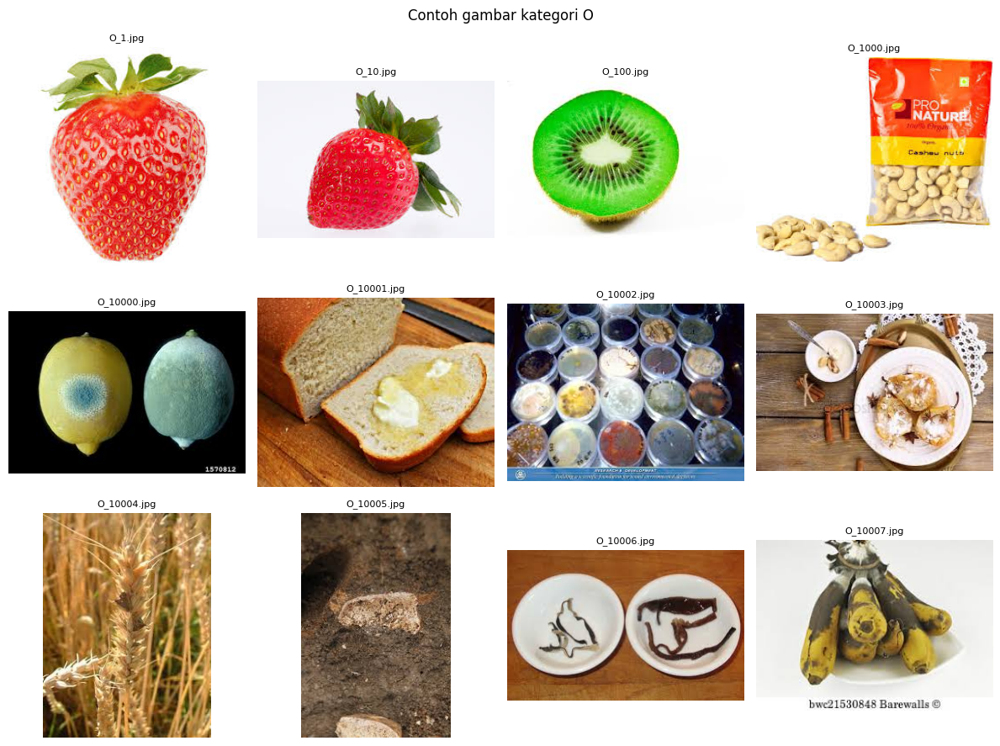


LABEL: R
Jumlah gambar: 22222

Contoh path:
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/R/R_1.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/R/R_10.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/R/R_100.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/R/R_1000.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/organik_anorganik/dataset/DATASET/TRAIN/R/R_1001.jpg


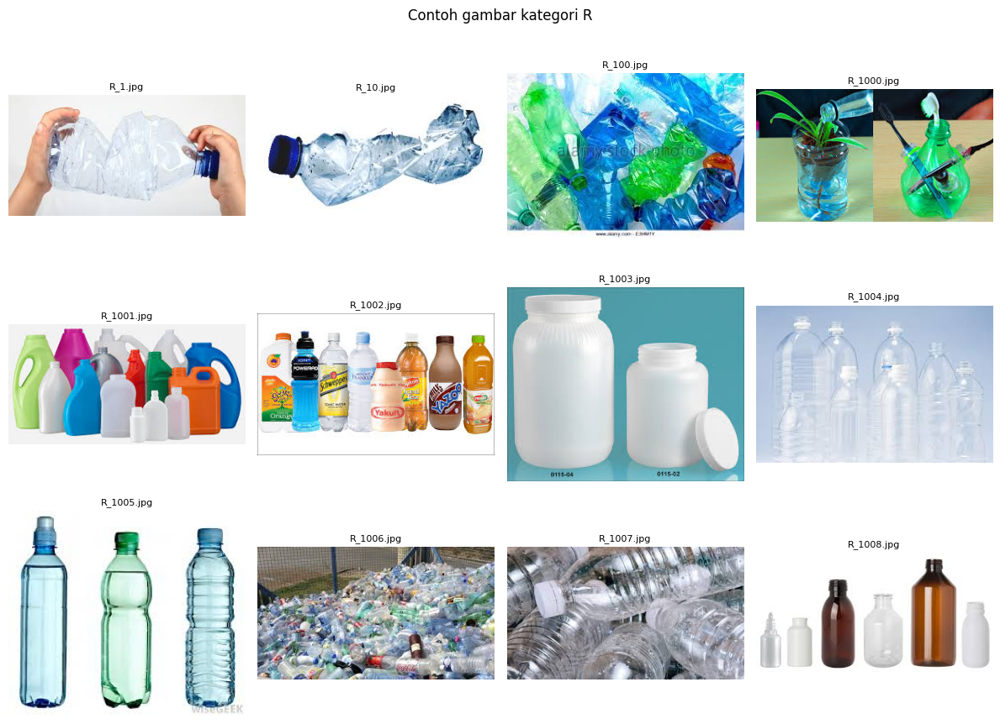

In [12]:
# ============================================================
# INSPEKSI GAMBAR KATEGORI O DAN R
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

org_source = raw_manifest[
    raw_manifest["source_id"]
    == "eldadvikorian/dataset-sampah-organik-dan-anorganik"
]

for label in ["O", "R"]:
    sample = org_source[
        org_source["original_label"] == label
    ].head(12)

    print(f"\n{'=' * 60}")
    print(f"LABEL: {label}")
    print("Jumlah gambar:", len(org_source[
        org_source["original_label"] == label
    ]))

    print("\nContoh path:")
    for path in sample["raw_path"].head(5):
        print(path)

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    fig.suptitle(f"Contoh gambar kategori {label}")

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        try:
            img = Image.open(row["raw_path"]).convert("RGB")
            ax.imshow(img)
            ax.set_title(Path(row["raw_path"]).name, fontsize=8)
        except Exception:
            ax.set_title("Gagal dibaca")

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [13]:
# ============================================================
# PERBARUI PEMETAAN LABEL ORGANIK
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

source_id = "eldadvikorian/dataset-sampah-organik-dan-anorganik"

mapping_table.loc[
    (mapping_table["source_id"] == source_id)
    & (mapping_table["original_label"] == "O"),
    "mapped_label"
] = "organik"

mapping_table.loc[
    (mapping_table["source_id"] == source_id)
    & (mapping_table["original_label"] == "O"),
    "mapping_status"
] = "mapped"

mapping_table.to_csv(mapping_path, index=False)

print("Pemetaan O berhasil diperbarui.")

Pemetaan O berhasil diperbarui.


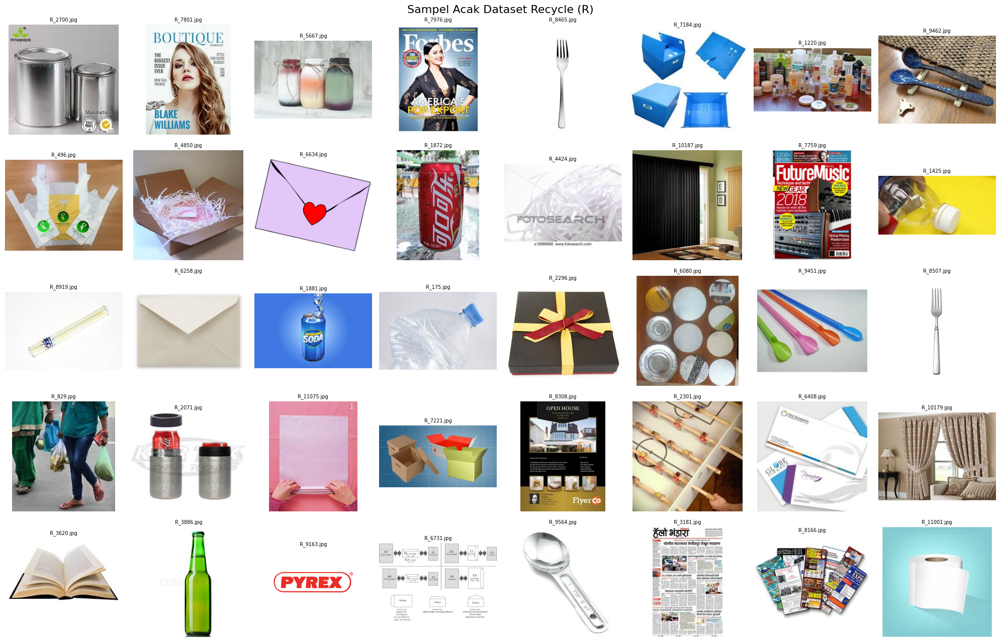

In [14]:
# ============================================================
# INSPEKSI ACAK KATEGORI R
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

r_samples = raw_manifest[
    (raw_manifest["source_id"] == source_id)
    & (raw_manifest["original_label"] == "R")
].sample(
    n=40,
    random_state=42
)

fig, axes = plt.subplots(5, 8, figsize=(20, 13))

for ax, (_, row) in zip(axes.flat, r_samples.iterrows()):
    try:
        img = Image.open(row["raw_path"]).convert("RGB")
        ax.imshow(img)
    except Exception:
        ax.text(0.5, 0.5, "Error", ha="center")

    ax.set_title(Path(row["raw_path"]).name, fontsize=7)
    ax.axis("off")

plt.suptitle("Sampel Acak Dataset Recycle (R)", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# PERBARUI PEMETAAN ORGANIK DAN RECYCLE
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

source_id = "eldadvikorian/dataset-sampah-organik-dan-anorganik"

# O = Organik
mapping_table.loc[
    (mapping_table["source_id"] == source_id)
    & (mapping_table["original_label"] == "O"),
    ["mapped_label", "mapping_status"]
] = ["organik", "mapped"]

# R = Recycle (kategori terlalu heterogen)
mapping_table.loc[
    (mapping_table["source_id"] == source_id)
    & (mapping_table["original_label"] == "R"),
    ["mapped_label", "mapping_status"]
] = ["", "exclude"]

# Kaca pada dataset Sampah Daur Ulang
mapping_table.loc[
    (mapping_table["source_id"] == "fathurrahmanalfarizy/sampah-daur-ulang")
    & (mapping_table["original_label"] == "Kaca"),
    ["mapped_label", "mapping_status"]
] = ["Kaca", "mapped"]

mapping_table.to_csv(mapping_path, index=False)

print("Pembaruan pemetaan berhasil.")
display(
    mapping_table[
        ["source_dataset", "original_label", "mapped_label", "mapping_status"]
    ]
)

Pembaruan pemetaan berhasil.


,source_dataset,original_label,mapped_label,mapping_status
0,Sampah Daur Ulang,Kaca,Kaca,mapped
1,Sampah Daur Ulang,Kardus,Kardus,mapped
2,Sampah Daur Ulang,Kertas,Kertas,mapped
3,Sampah Daur Ulang,Logam,Logam,mapped
4,Sampah Daur Ulang,Plastik,Plastik,mapped
5,Sampah Daur Ulang,Residu,,review
6,Medical Waste Dataset Annotated,gauze,,review
7,Medical Waste Dataset Annotated,glove_pair_latex,,review
8,Medical Waste Dataset Annotated,glove_pair_nitrile,,review
9,Medical Waste Dataset Annotated,glove_pair_surgery,,review


In [16]:
# ============================================================
# PERBARUI LABEL YANG SUDAH DIPUTUSKAN
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

# Label yang dikeluarkan
exclude_labels = {
    (
        "fathurrahmanalfarizy/sampah-daur-ulang",
        "Residu"
    ),
    (
        "mostafaabla/garbage-classification",
        "clothes"
    ),
    (
        "mostafaabla/garbage-classification",
        "shoes"
    ),
    (
        "mostafaabla/garbage-classification",
        "trash"
    ),
}

for source, label in exclude_labels:
    mask = (
        (mapping_table["source_id"] == source)
        & (mapping_table["original_label"] == label)
    )

    mapping_table.loc[
        mask, ["mapped_label", "mapping_status"]
    ] = ["", "exclude"]

# Battery belum diputuskan otomatis.
# Tetap review sampai definisi B3 dan kondisi objek dipastikan.

mapping_table.to_csv(mapping_path, index=False)

print("Pembaruan label berhasil.")
display(
    mapping_table[
        ["source_dataset", "original_label",
         "mapped_label", "mapping_status"]
    ]
)

Pembaruan label berhasil.


,source_dataset,original_label,mapped_label,mapping_status
0,Sampah Daur Ulang,Kaca,Kaca,mapped
1,Sampah Daur Ulang,Kardus,Kardus,mapped
2,Sampah Daur Ulang,Kertas,Kertas,mapped
3,Sampah Daur Ulang,Logam,Logam,mapped
4,Sampah Daur Ulang,Plastik,Plastik,mapped
5,Sampah Daur Ulang,Residu,,exclude
6,Medical Waste Dataset Annotated,gauze,,review
7,Medical Waste Dataset Annotated,glove_pair_latex,,review
8,Medical Waste Dataset Annotated,glove_pair_nitrile,,review
9,Medical Waste Dataset Annotated,glove_pair_surgery,,review


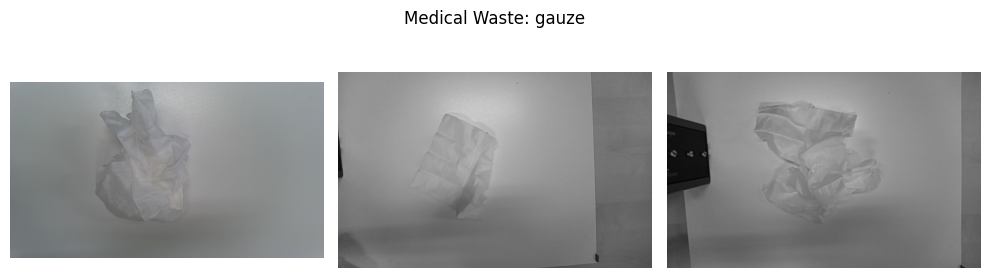

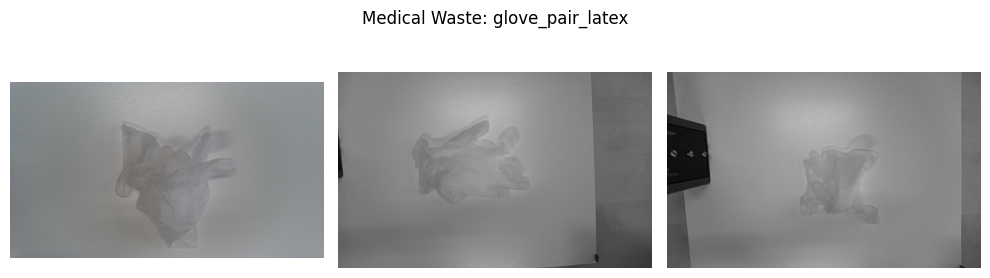

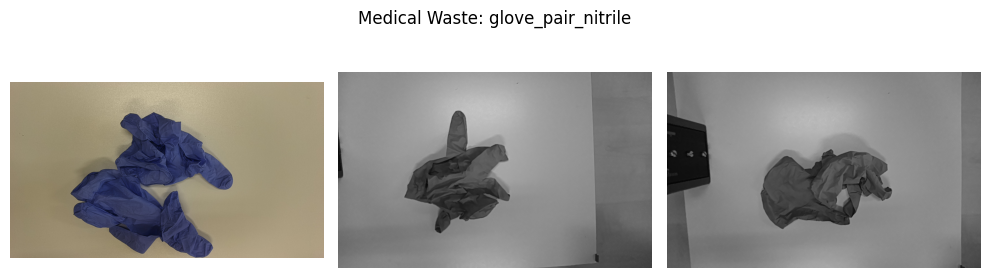

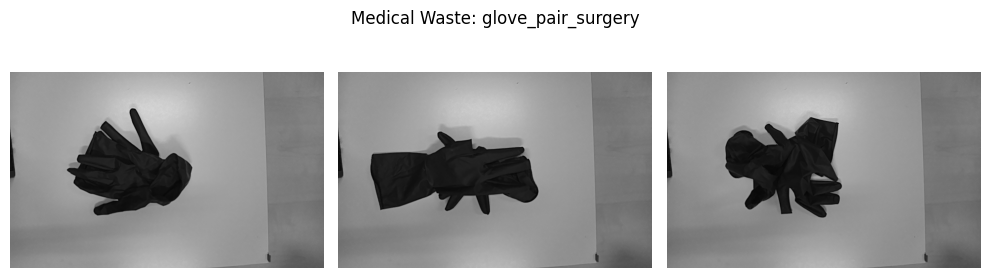

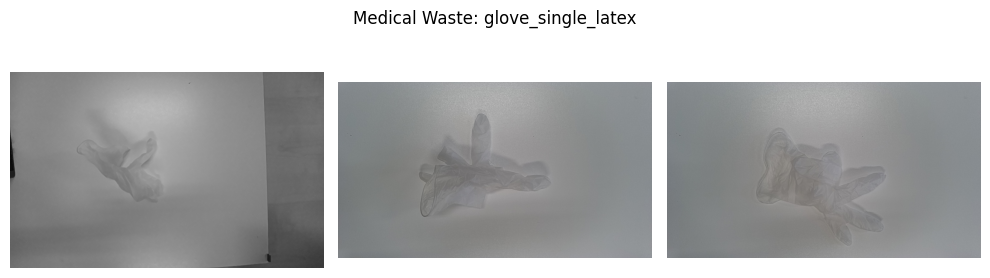

...

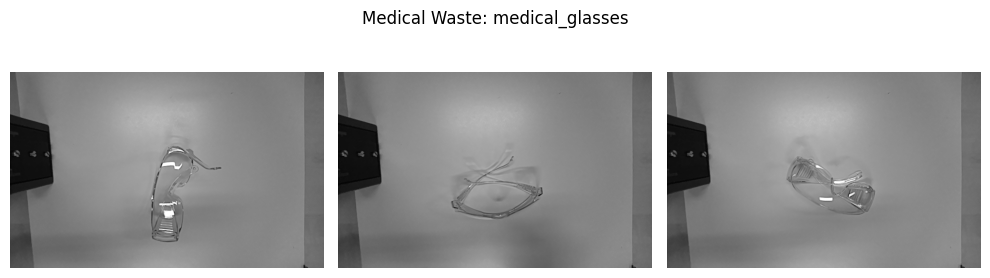

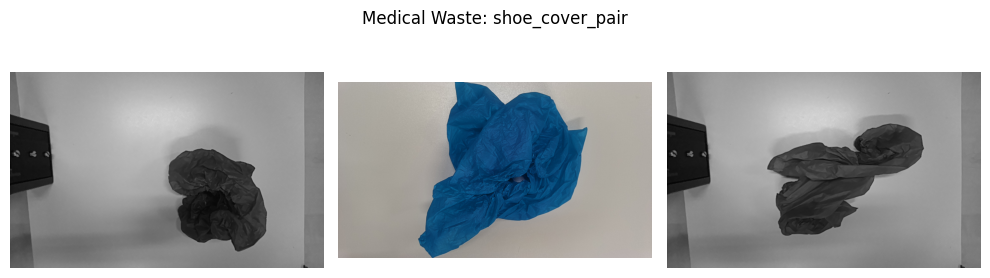

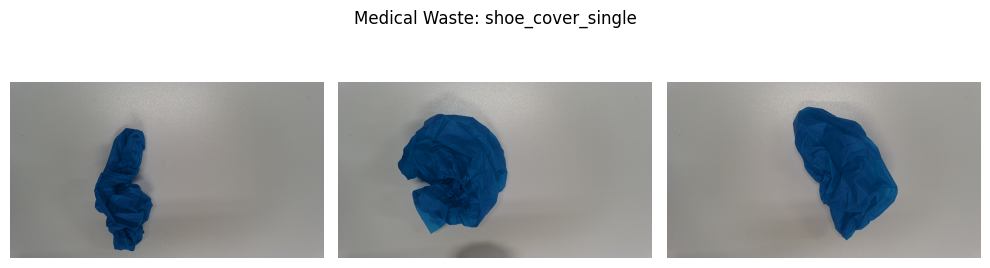

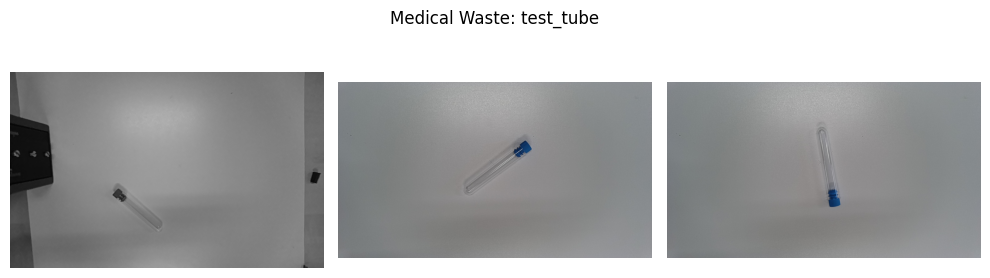

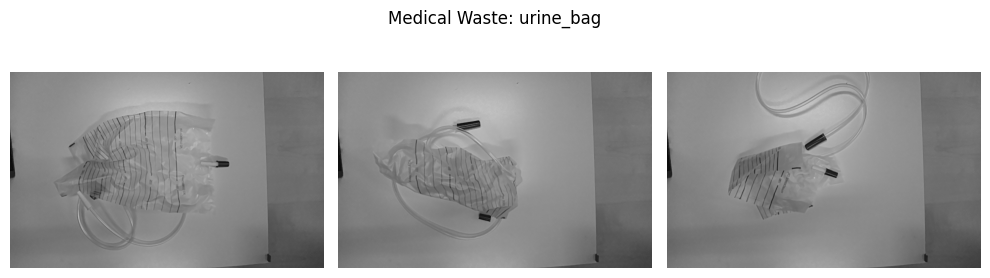

In [17]:
# ============================================================
# INSPEKSI SAMPEL MEDICAL WASTE
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

medical_source = (
    "dsaivarun/medical-waste-dataset-annotated"
)

medical_data = raw_manifest[
    raw_manifest["source_id"] == medical_source
]

medical_labels = sorted(
    medical_data["original_label"].unique()
)

for label in medical_labels:

    samples = medical_data[
        medical_data["original_label"] == label
    ].sample(
        n=min(3, len(medical_data[
            medical_data["original_label"] == label
        ])),
        random_state=42
    )

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    fig.suptitle(f"Medical Waste: {label}")

    for ax, (_, row) in zip(axes, samples.iterrows()):
        try:
            img = Image.open(row["raw_path"]).convert("RGB")
            ax.imshow(img)
        except Exception:
            ax.set_title("Gagal dibaca")

        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [18]:
# ============================================================
# FINALISASI PEMETAAN MEDICAL WASTE
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

medical_source = "dsaivarun/medical-waste-dataset-annotated"

medical_labels = [
    "gauze",
    "glove_pair_latex",
    "glove_pair_nitrile",
    "glove_pair_surgery",
    "glove_single_latex",
    "glove_single_nitrile",
    "glove_single_surgery",
    "medical_cap",
    "medical_glasses",
    "shoe_cover_pair",
    "shoe_cover_single",
    "test_tube",
    "urine_bag",
]

mask = (
    (mapping_table["source_id"] == medical_source)
    & (mapping_table["original_label"].isin(medical_labels))
)

mapping_table.loc[
    mask, ["mapped_label", "mapping_status"]
] = ["Medis", "mapped"]

# Pastikan seluruh kategori ditemukan
found_labels = set(
    mapping_table.loc[mask, "original_label"]
)

missing_labels = set(medical_labels) - found_labels

if missing_labels:
    raise RuntimeError(
        f"Kategori Medical Waste tidak ditemukan: {missing_labels}"
    )

mapping_table.to_csv(mapping_path, index=False)

print("Seluruh kategori Medical Waste berhasil dipetakan ke Medis.")
display(
    mapping_table.loc[
        mask,
        ["original_label", "mapped_label", "mapping_status"]
    ]
)

Seluruh kategori Medical Waste berhasil dipetakan ke Medis.


,original_label,mapped_label,mapping_status
6,gauze,Medis,mapped
7,glove_pair_latex,Medis,mapped
8,glove_pair_nitrile,Medis,mapped
9,glove_pair_surgery,Medis,mapped
10,glove_single_latex,Medis,mapped
11,glove_single_nitrile,Medis,mapped
12,glove_single_surgery,Medis,mapped
13,medical_cap,Medis,mapped
14,medical_glasses,Medis,mapped
15,shoe_cover_pair,Medis,mapped


In [19]:
# ============================================================
# PEMETAAN BATTERY KE B3
# ============================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

mask = (
    (mapping_table["source_id"] ==
     "mostafaabla/garbage-classification")
    & (mapping_table["original_label"] == "battery")
)

mapping_table.loc[
    mask, ["mapped_label", "mapping_status"]
] = ["B3", "mapped"]

if not mask.any():
    raise RuntimeError("Label battery tidak ditemukan.")

mapping_table.to_csv(mapping_path, index=False)

print("Battery berhasil dipetakan ke B3.")

Battery berhasil dipetakan ke B3.


Jumlah gambar: 9958
Jumlah gambar valid: 9958

Contoh lokasi gambar:
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image10.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image100.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1013.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1014.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1018.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1019.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1021.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1023.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1024.jpg
/content/drive/MyDrive/REKLE_Rebuild/raw/random_images/dataset/test/image1029.jpg


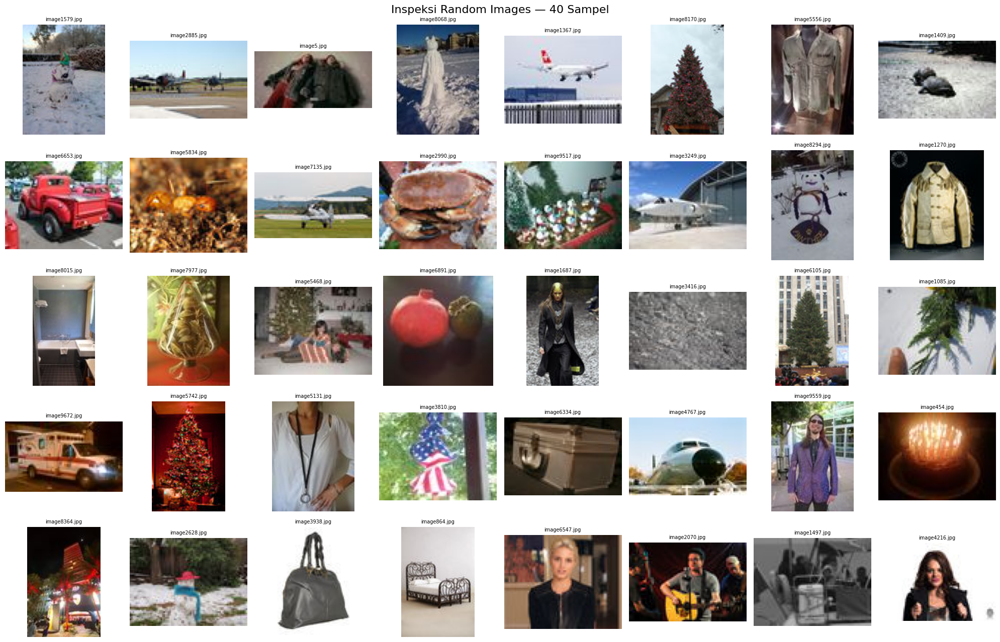

In [20]:
# ============================================================
# INSPEKSI DATASET RANDOM IMAGES
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

random_source = "ezzzio/random-images"

random_data = raw_manifest[
    raw_manifest["source_id"] == random_source
].copy()

print("Jumlah gambar:", len(random_data))
print("Jumlah gambar valid:", random_data["is_valid_image"].sum())

print("\nContoh lokasi gambar:")
for path in random_data["raw_path"].head(10):
    print(path)

# Ambil 40 sampel acak
random_samples = random_data.sample(
    n=min(40, len(random_data)),
    random_state=42
)

fig, axes = plt.subplots(5, 8, figsize=(20, 13))
fig.suptitle("Inspeksi Random Images — 40 Sampel", fontsize=16)

for ax, (_, row) in zip(axes.flat, random_samples.iterrows()):
    try:
        img = Image.open(row["raw_path"]).convert("RGB")
        ax.imshow(img)
    except Exception:
        ax.text(0.5, 0.5, "Gagal dibaca", ha="center")

    ax.set_title(Path(row["raw_path"]).name, fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# KURASI RANDOM IMAGES UNTUK KELAS NONSAMPAH
# ============================================================

random_source = "ezzzio/random-images"

random_manifest = raw_manifest[
    (raw_manifest["source_id"] == random_source)
    & (raw_manifest["is_valid_image"])
].copy()

random_manifest["mapped_label"] = ""
random_manifest["mapping_status"] = "review"
random_manifest["review_note"] = ""

review_path = os.path.join(
    DRIVE_DIR,
    "random_images_review.csv"
)

random_manifest.to_csv(review_path, index=False)

print("Manifest kurasi berhasil dibuat.")
print("Jumlah gambar:", len(random_manifest))
print("Lokasi:", review_path)

Manifest kurasi berhasil dibuat.
Jumlah gambar: 9958
Lokasi: /content/drive/MyDrive/REKLE_Rebuild/random_images_review.csv


Batch: 1
Gambar: 1 sampai 100
Total batch: 100


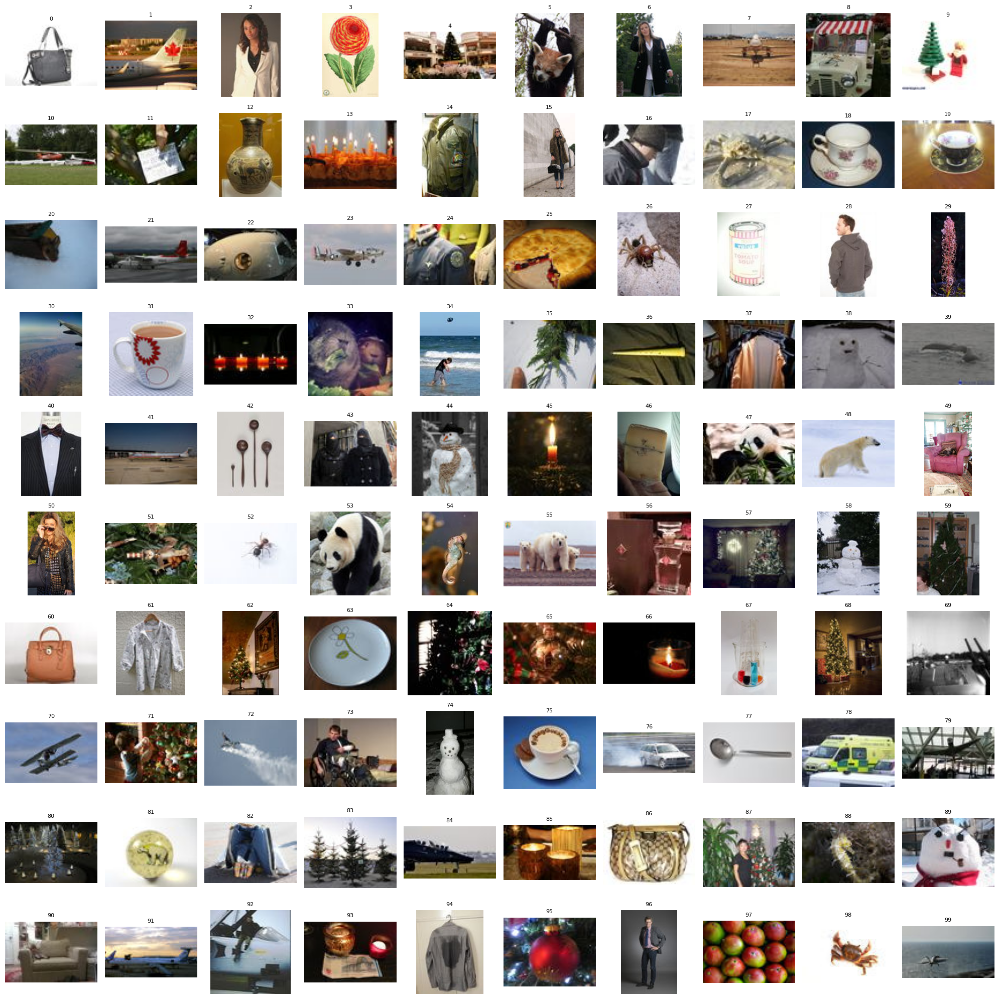

In [22]:
# ============================================================
# TAMPILKAN BATCH KURASI RANDOM IMAGES
# ============================================================

import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

review_path = os.path.join(
    DRIVE_DIR,
    "random_images_review.csv"
)

random_review = pd.read_csv(review_path).fillna("")

BATCH_SIZE = 100
BATCH_NUMBER = 0  # Ubah ke 1, 2, 3, dan seterusnya

start = BATCH_NUMBER * BATCH_SIZE
end = min(start + BATCH_SIZE, len(random_review))

batch = random_review.iloc[start:end]

print(f"Batch: {BATCH_NUMBER + 1}")
print(f"Gambar: {start + 1} sampai {end}")
print(f"Total batch: {math.ceil(len(random_review) / BATCH_SIZE)}")

fig, axes = plt.subplots(10, 10, figsize=(20, 20))

for ax, (idx, row) in zip(axes.flat, batch.iterrows()):
    try:
        img = Image.open(row["raw_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(str(idx), fontsize=8)
    except Exception:
        ax.set_title("ERROR")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# CELL — Tetapkan seluruh Random Images sebagai nonsampah

import os
import pandas as pd

REVIEW_PATH = os.path.join(DRIVE_DIR, "random_images_review.csv")

random_review = pd.read_csv(REVIEW_PATH).fillna("")

# Pastikan semua baris berasal dari sumber Random Images
assert len(random_review) == 9958, (
    f"Jumlah gambar berubah: {len(random_review)}"
)

# Tetapkan seluruh gambar sebagai nonsampah
random_review["mapped_label"] = "nonsampah"
random_review["mapping_status"] = "mapped"
random_review["review_note"] = (
    "Ditetapkan sebagai nonsampah berdasarkan keputusan penelitian"
)

random_review.to_csv(REVIEW_PATH, index=False)

print("Pemetaan Random Images berhasil disimpan.")
print("Total gambar:", len(random_review))
print("\nDistribusi label:")
display(random_review["mapped_label"].value_counts())
print("\nDistribusi status:")
display(random_review["mapping_status"].value_counts())
print("\nFile:", REVIEW_PATH)

Pemetaan Random Images berhasil disimpan.
Total gambar: 9958

Distribusi label:


,count
mapped_label,
nonsampah,9958



Distribusi status:


,count
mapping_status,
mapped,9958



File: /content/drive/MyDrive/REKLE_Rebuild/random_images_review.csv


In [24]:
# Tetapkan battery sebagai B3 jika sesuai definisi operasional penelitian

mapping_table = pd.read_csv(mapping_path).fillna("")

mask = (
    (mapping_table["source_id"] == "mostafaabla/garbage-classification")
    & (mapping_table["original_label"] == "battery")
)

if mask.sum() != 1:
    raise RuntimeError("Label battery tidak ditemukan secara unik.")

mapping_table.loc[mask, "mapped_label"] = "B3"
mapping_table.loc[mask, "mapping_status"] = "mapped"

mapping_table.to_csv(mapping_path, index=False)

print("Pemetaan battery → B3 berhasil disimpan.")

Pemetaan battery → B3 berhasil disimpan.


In [25]:
# CELL 6 — Integrasi pemetaan dan bangun dataset 9 kelas

import os
import shutil
import hashlib
import pandas as pd
from pathlib import Path

# =========================================================
# 1. BACA FILE PEMETAAN
# =========================================================

mapping_table = pd.read_csv(mapping_path).fillna("")

RANDOM_SOURCE = "ezzzio/random-images"
SYNTHETIC_LABEL = "__ROOT_OR_ANNOTATION_BASED__"

RANDOM_REVIEW_PATH = os.path.join(
    DRIVE_DIR, "random_images_review.csv"
)

random_review = pd.read_csv(RANDOM_REVIEW_PATH).fillna("")

allowed_classes = set(CLASS_NAMES_FIXED)
allowed_statuses = {"mapped", "exclude", "review"}

required_mapping_cols = {
    "source_id", "original_label",
    "mapped_label", "mapping_status"
}

required_random_cols = {
    "source_id", "raw_path",
    "mapped_label", "mapping_status"
}

if not required_mapping_cols.issubset(mapping_table.columns):
    raise RuntimeError("Kolom label_mapping_review.csv tidak lengkap.")

if not required_random_cols.issubset(random_review.columns):
    raise RuntimeError("Kolom random_images_review.csv tidak lengkap.")

# =========================================================
# 2. VALIDASI PEMETAAN UMUM
# =========================================================

if mapping_table.duplicated(
    subset=["source_id", "original_label"]
).any():
    raise RuntimeError(
        "Ditemukan duplikasi kombinasi source_id dan original_label."
    )

invalid_status = mapping_table[
    ~mapping_table["mapping_status"].isin(allowed_statuses)
]

if not invalid_status.empty:
    display(invalid_status)
    raise RuntimeError("Ada mapping_status yang tidak valid.")

invalid_mapped = mapping_table[
    (mapping_table["mapping_status"] == "mapped")
    & (~mapping_table["mapped_label"].isin(allowed_classes))
]

if not invalid_mapped.empty:
    display(invalid_mapped)
    raise RuntimeError("Ada mapped_label yang tidak termasuk 9 kelas.")

invalid_exclude = mapping_table[
    (mapping_table["mapping_status"] == "exclude")
    & (mapping_table["mapped_label"] != "")
]

if not invalid_exclude.empty:
    display(invalid_exclude)
    raise RuntimeError("Baris exclude harus memiliki mapped_label kosong.")

# Baris sintetis Random Images tidak dipakai dalam mapping umum.
normal_mapping = mapping_table[
    ~(
        (mapping_table["source_id"] == RANDOM_SOURCE)
        & (mapping_table["original_label"] == SYNTHETIC_LABEL)
    )
].copy()

# Hentikan proses jika masih ada label yang perlu ditinjau.
pending_mapping = normal_mapping[
    normal_mapping["mapping_status"] == "review"
]

if not pending_mapping.empty:
    print("Masih ada label yang belum diputuskan:")
    display(
        pending_mapping[
            ["source_id", "original_label", "mapped_label", "mapping_status"]
        ]
    )
    raise RuntimeError(
        "Selesaikan seluruh mapping_status review sebelum membangun dataset."
    )

# =========================================================
# 3. VALIDASI RANDOM IMAGES
# =========================================================

if random_review.duplicated(subset=["raw_path"]).any():
    raise RuntimeError("Ada raw_path duplikat pada random_images_review.csv.")

invalid_random_status = random_review[
    ~random_review["mapping_status"].isin(allowed_statuses)
]

if not invalid_random_status.empty:
    display(invalid_random_status)
    raise RuntimeError("Status kurasi Random Images tidak valid.")

invalid_random_label = random_review[
    (random_review["mapping_status"] == "mapped")
    & (~random_review["mapped_label"].isin(allowed_classes))
]

if not invalid_random_label.empty:
    display(invalid_random_label)
    raise RuntimeError("Ada label Random Images yang tidak valid.")

if (
    (random_review["mapping_status"] == "exclude")
    & (random_review["mapped_label"] != "")
).any():
    raise RuntimeError("Baris Random Images berstatus exclude harus kosong labelnya.")

pending_random = random_review[
    random_review["mapping_status"] == "review"
]

if not pending_random.empty:
    display(pending_random.head(20))
    raise RuntimeError(
        "Masih ada gambar Random Images yang belum dikurasi."
    )

if not (random_review["source_id"] == RANDOM_SOURCE).all():
    raise RuntimeError("Ditemukan source_id yang bukan Random Images.")

# Pastikan semua gambar Random Images pada raw_manifest
# sudah memiliki keputusan kurasi.
raw_random = raw_manifest[
    (raw_manifest["source_id"] == RANDOM_SOURCE)
    & (raw_manifest["is_valid_image"])
]

raw_random_paths = set(raw_random["raw_path"].astype(str))
review_random_paths = set(random_review["raw_path"].astype(str))

if raw_random_paths != review_random_paths:
    raise RuntimeError(
        "Daftar gambar Random Images pada manifest dan CSV kurasi tidak sama."
    )

# =========================================================
# 4. TERAPKAN PEMETAAN KE RAW MANIFEST
# =========================================================

map_lookup = {
    (row.source_id, row.original_label): (
        row.mapped_label, row.mapping_status
    )
    for row in normal_mapping.itertuples(index=False)
}

raw_manifest = raw_manifest.copy()
raw_manifest["mapped_label"] = ""
raw_manifest["mapping_status"] = ""
raw_manifest["review_note"] = ""

unknown_labels = []

for idx, row in raw_manifest.iterrows():

    # Random Images menggunakan label per gambar.
    if row["source_id"] == RANDOM_SOURCE:
        continue

    key = (row["source_id"], row["original_label"])

    if key not in map_lookup:
        unknown_labels.append(key)
        continue

    mapped_label, status = map_lookup[key]

    raw_manifest.at[idx, "mapped_label"] = mapped_label
    raw_manifest.at[idx, "mapping_status"] = status

if unknown_labels:
    print("Label sumber yang belum tercantum di tabel mapping:")
    display(pd.DataFrame(
        unknown_labels,
        columns=["source_id", "original_label"]
    ).drop_duplicates())

    raise RuntimeError("Tambahkan label tersebut ke label_mapping_review.csv.")

# Terapkan hasil kurasi Random Images berdasarkan raw_path.
random_lookup = random_review.set_index("raw_path")

for idx, row in raw_manifest[
    raw_manifest["source_id"] == RANDOM_SOURCE
].iterrows():

    path = row["raw_path"]

    if path not in random_lookup.index:
        continue

    reviewed = random_lookup.loc[path]

    raw_manifest.at[idx, "mapped_label"] = reviewed["mapped_label"]
    raw_manifest.at[idx, "mapping_status"] = reviewed["mapping_status"]

    if "review_note" in random_review.columns:
        raw_manifest.at[idx, "review_note"] = reviewed["review_note"]

# =========================================================
# 5. BENTUK MANIFEST VALID
# =========================================================

valid_manifest = raw_manifest[
    (raw_manifest["is_valid_image"])
    & (raw_manifest["mapping_status"] == "mapped")
    & (raw_manifest["mapped_label"].isin(allowed_classes))
].copy()

if valid_manifest.empty:
    raise RuntimeError("Tidak ada gambar valid yang berhasil dipetakan.")

# =========================================================
# 6. PERIKSA JUMLAH GAMBAR SETIAP KELAS
# =========================================================

class_counts = {
    class_name: int(
        (valid_manifest["mapped_label"] == class_name).sum()
    )
    for class_name in CLASS_NAMES_FIXED
}

display(pd.DataFrame({
    "kelas": CLASS_NAMES_FIXED,
    "jumlah_gambar": [
        class_counts[c] for c in CLASS_NAMES_FIXED
    ]
}))

absent_classes = [
    c for c, count in class_counts.items()
    if count == 0
]

if absent_classes:
    raise RuntimeError(
        f"Kelas berikut belum memiliki gambar: {absent_classes}"
    )

# =========================================================
# 7. BANGUN FOLDER DATASET
# =========================================================

shutil.rmtree(DATA_DIR, ignore_errors=True)

for row in valid_manifest.itertuples(index=False):

    suffix = Path(row.raw_path).suffix.lower()

    unique_name = hashlib.sha1(
        (row.source_id + "|" + row.raw_path).encode()
    ).hexdigest()[:20] + suffix

    target_dir = Path(DATA_DIR) / row.mapped_label
    target_dir.mkdir(parents=True, exist_ok=True)

    target_path = target_dir / unique_name

    shutil.copy2(row.raw_path, target_path)

    raw_manifest.loc[
        raw_manifest["raw_path"] == row.raw_path,
        "unified_path"
    ] = str(target_path)

# =========================================================
# 8. SIMPAN MANIFEST
# =========================================================

manifest_all_path = os.path.join(
    DRIVE_DIR, "image_source_manifest.csv"
)

manifest_valid_path = os.path.join(
    DRIVE_DIR, "image_source_manifest_valid.csv"
)

raw_manifest.to_csv(manifest_all_path, index=False)
valid_manifest.to_csv(manifest_valid_path, index=False)

print("\nDataset berhasil dibangun.")
print("Total gambar valid:", len(valid_manifest))
print("Distribusi kelas:")

display(pd.DataFrame({
    "kelas": CLASS_NAMES_FIXED,
    "jumlah": [class_counts[c] for c in CLASS_NAMES_FIXED]
}))

print("Manifest lengkap:", manifest_all_path)
print("Manifest valid:", manifest_valid_path)
print("Folder dataset:", DATA_DIR)

,kelas,jumlah_gambar
0,B3,945
1,Kaca,3121
2,Kardus,1515
3,Kertas,2857
4,Logam,1979
5,Medis,4245
6,Plastik,2122
7,nonsampah,9958
8,organik,28917



Dataset berhasil dibangun.
Total gambar valid: 55659
Distribusi kelas:


,kelas,jumlah
0,B3,945
1,Kaca,3121
2,Kardus,1515
3,Kertas,2857
4,Logam,1979
5,Medis,4245
6,Plastik,2122
7,nonsampah,9958
8,organik,28917


Manifest lengkap: /content/drive/MyDrive/REKLE_Rebuild/image_source_manifest.csv
Manifest valid: /content/drive/MyDrive/REKLE_Rebuild/image_source_manifest_valid.csv
Folder dataset: /content/dataset_rekle_mapped


Jumlah file gambar rusak yang dihapus: 0

Distribusi gambar per kelas:
    Kelas  Jumlah  Persentase
       B3     945    1.697839
     Kaca    3121    5.607359
   Kardus    1515    2.721932
   Kertas    2857    5.133042
    Logam    1979    3.555580
    Medis    4245    7.626799
  Plastik    2122    3.812501
nonsampah    9958   17.891087
  organik   28917   51.953862

Total gambar valid: 55659
Rasio kelas terbesar/terkecil: 30.6


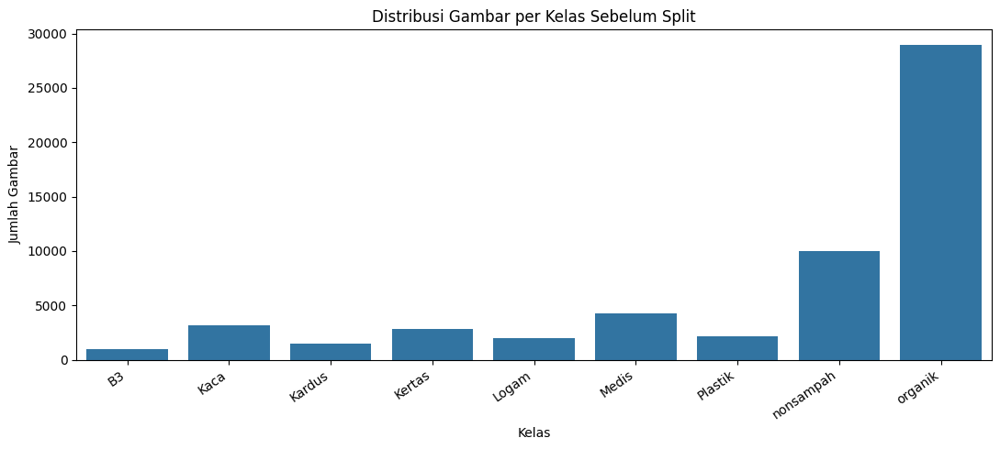


Laporan file rusak: /content/drive/MyDrive/REKLE_Rebuild/corrupt_files_removed.csv
Grafik distribusi: /content/drive/MyDrive/REKLE_Rebuild/class_distribution.png


In [26]:

# CELL 5 — Validasi gambar dan hitung distribusi kelas

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
removed_files = []

# Pastikan variabel kelas dan direktori sudah tersedia
if "CLASS_NAMES_FIXED" not in globals():
    raise NameError("CLASS_NAMES_FIXED belum didefinisikan. Jalankan cell konfigurasi.")

if not Path(DATA_DIR).exists():
    raise FileNotFoundError(
        f"Folder dataset belum tersedia: {DATA_DIR}. Jalankan CELL 6 terlebih dahulu."
    )

# Validasi setiap kelas
for class_name in CLASS_NAMES_FIXED:
    class_dir = Path(DATA_DIR) / class_name

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Folder kelas tidak ditemukan: {class_dir}"
        )

    for path in list(class_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in VALID_EXT:
            continue

        try:
            with Image.open(path) as im:
                im.verify()

        except Exception:
            removed_files.append(str(path))
            path.unlink(missing_ok=True)

print("Jumlah file gambar rusak yang dihapus:", len(removed_files))

# Simpan catatan file rusak di Google Drive
corrupt_report_path = os.path.join(
    DRIVE_DIR, "corrupt_files_removed.csv"
)

pd.DataFrame({
    "file_dihapus": removed_files
}).to_csv(corrupt_report_path, index=False)

# Hitung distribusi gambar setiap kelas
class_counts = {}

for class_name in CLASS_NAMES_FIXED:
    class_dir = Path(DATA_DIR) / class_name

    count = sum(
        1 for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXT
    )

    class_counts[class_name] = count

counts_df = pd.DataFrame({
    "Kelas": list(class_counts.keys()),
    "Jumlah": list(class_counts.values())
})

total_images = counts_df["Jumlah"].sum()

if total_images == 0:
    raise RuntimeError("Tidak ditemukan gambar valid dalam dataset.")

counts_df["Persentase"] = (
    100 * counts_df["Jumlah"] / total_images
)

print("\nDistribusi gambar per kelas:")
print(counts_df.to_string(index=False))

print("\nTotal gambar valid:", int(total_images))

min_count = counts_df["Jumlah"].min()
max_count = counts_df["Jumlah"].max()

if min_count == 0:
    print("Rasio kelas terbesar/terkecil: tidak dapat dihitung karena ada kelas kosong.")
else:
    print(
        "Rasio kelas terbesar/terkecil:",
        round(max_count / min_count, 2)
    )

# Visualisasi distribusi kelas
plt.figure(figsize=(11, 5))

sns.barplot(
    data=counts_df,
    x="Kelas",
    y="Jumlah"
)

plt.title("Distribusi Gambar per Kelas Sebelum Split")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plot_path = os.path.join(
    DRIVE_DIR, "class_distribution.png"
)

plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("\nLaporan file rusak:", corrupt_report_path)
print("Grafik distribusi:", plot_path)


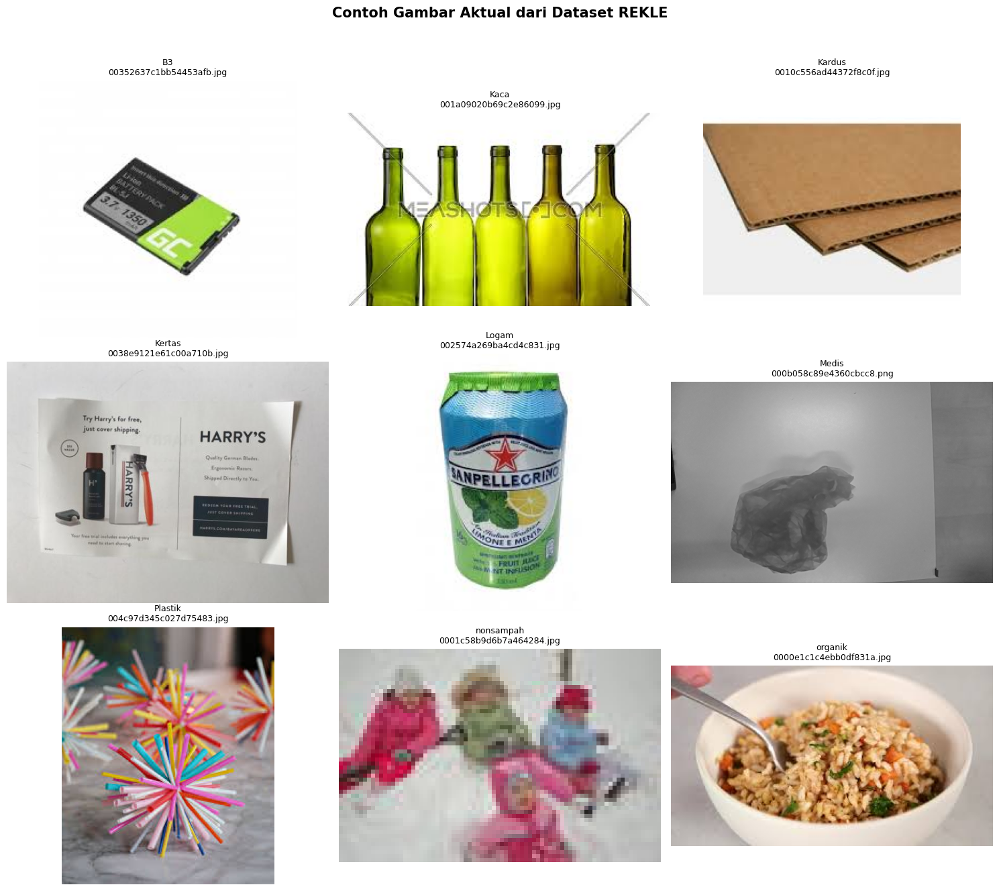

Visualisasi sampel berhasil dibuat.
Lokasi: /content/drive/MyDrive/REKLE_Rebuild/dataset_sample_grid.png


In [27]:

# CELL 6 — Visualisasi sampel gambar dari setiap kelas

import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ncols = 3
nrows = math.ceil(len(CLASS_NAMES_FIXED) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 4.5 * nrows)
)

axes = np.array(axes).reshape(-1)

for ax, class_name in zip(axes, CLASS_NAMES_FIXED):

    class_dir = Path(DATA_DIR) / class_name

    ax.axis("off")

    if not class_dir.exists():
        ax.set_title(f"{class_name}\nFolder tidak ditemukan")
        continue

    candidates = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXT
    ]

    if candidates:
        sample_path = sorted(candidates)[0]

        try:
            with Image.open(sample_path) as im:
                ax.imshow(im.convert("RGB"))

            ax.set_title(
                f"{class_name}\n{sample_path.name}",
                fontsize=9
            )

        except Exception as e:
            ax.set_title(
                f"{class_name}\nGagal membuka gambar",
                fontsize=9
            )

    else:
        ax.set_title(
            f"{class_name}\nTidak ada gambar",
            fontsize=9
        )

# Matikan subplot yang tidak digunakan
for ax in axes[len(CLASS_NAMES_FIXED):]:
    ax.axis("off")

plt.suptitle(
    "Contoh Gambar Aktual dari Dataset REKLE",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

sample_grid_path = os.path.join(
    DRIVE_DIR,
    "dataset_sample_grid.png"
)

plt.savefig(
    sample_grid_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Visualisasi sampel berhasil dibuat.")
print("Lokasi:", sample_grid_path)


In [28]:
# CELL 9 — Ringkasan metadata sumber aktual (bukan placeholder)
source_metadata = (
    valid_manifest.groupby(["source_dataset", "source_url", "mapped_label"], as_index=False)
    .agg(Jumlah_gambar=("file_name", "count"),
         Label_asli=("original_label", lambda x: ", ".join(sorted(set(map(str, x))))))
    .sort_values(["source_dataset", "mapped_label"])
)
source_metadata.to_csv(os.path.join(DRIVE_DIR, "dataset_sources_actual.csv"), index=False)
display(source_metadata)
print("Lisensi dan ketentuan penggunaan tetap harus diverifikasi pada halaman setiap dataset sebelum publikasi.")


,source_dataset,source_url,mapped_label,Jumlah_gambar,Label_asli
0,Dataset Sampah Organik dan Anorganik,https://www.kaggle.com/datasets/eldadvikorian/...,organik,27932,O
1,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,B3,945,battery
2,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,Kaca,2011,"brown-glass, green-glass, white-glass"
3,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,Kardus,891,cardboard
4,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,Kertas,1050,paper
5,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,Logam,769,metal
6,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,Plastik,865,plastic
7,Garbage Classification,https://www.kaggle.com/datasets/mostafaabla/ga...,organik,985,biological
8,Medical Waste Dataset Annotated,https://www.kaggle.com/datasets/dsaivarun/medi...,Medis,4245,"gauze, glove_pair_latex, glove_pair_nitrile, g..."
9,Random Images,https://www.kaggle.com/datasets/ezzzio/random-...,nonsampah,9958,__ROOT_OR_ANNOTATION_BASED__


Lisensi dan ketentuan penggunaan tetap harus diverifikasi pada halaman setiap dataset sebelum publikasi.


In [29]:
# CELL 8 — Fungsi hash dan inventaris gambar untuk audit duplikasi

import hashlib
import numpy as np
from pathlib import Path
from PIL import Image

# Gunakan satu sumber nama kelas untuk seluruh notebook.
class_names = CLASS_NAMES_FIXED.copy()

# =========================================================
# 1. HASH MD5 UNTUK DUPLIKASI PERSIS
# =========================================================

def md5_file(path):
    """Menghasilkan hash MD5 dari isi file."""
    digest = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


# =========================================================
# 2. DIFFERENCE HASH (dHash) UNTUK KANDIDAT NEAR-DUPLICATE
# =========================================================

def dhash_bits(path, size=8):
    """Menghasilkan 64-bit dHash dari gambar."""
    with Image.open(path) as im:
        gray = im.convert("L").resize(
            (size + 1, size),
            Image.Resampling.LANCZOS
        )
        arr = np.asarray(gray, dtype=np.int16)

    return (
        (arr[:, 1:] > arr[:, :-1])
        .reshape(-1)
        .astype(np.uint8)
    )


# =========================================================
# 3. KUMPULKAN PATH DAN LABEL DARI FOLDER DATASET
# =========================================================

all_paths = []
all_labels = []
missing_classes = []

for label_id, class_name in enumerate(class_names):
    class_dir = Path(DATA_DIR) / class_name

    if not class_dir.exists():
        missing_classes.append(class_name)
        continue

    for path in sorted(class_dir.iterdir()):
        if path.is_file() and path.suffix.lower() in VALID_EXT:
            all_paths.append(str(path))
            all_labels.append(label_id)

if missing_classes:
    raise FileNotFoundError(
        f"Folder kelas tidak ditemukan: {missing_classes}"
    )

all_paths = np.asarray(all_paths, dtype=object)
all_labels = np.asarray(all_labels, dtype=np.int32)

if len(all_paths) == 0:
    raise RuntimeError("Tidak ada gambar untuk diaudit.")

# =========================================================
# 4. HITUNG dHash
# =========================================================

hash_rows = []
hash_errors = []

for i, path in enumerate(all_paths):
    try:
        hash_rows.append(dhash_bits(path))
    except Exception as exc:
        hash_errors.append({
            "path": str(path),
            "error": repr(exc)
        })

if hash_errors:
    error_path = os.path.join(DRIVE_DIR, "dhash_read_errors.csv")
    pd.DataFrame(hash_errors).to_csv(error_path, index=False)
    raise RuntimeError(
        f"{len(hash_errors)} gambar gagal dihitung dHash. "
        f"Periksa {error_path}, perbaiki dataset, lalu jalankan ulang CELL 5 dan CELL 8."
    )

hash_bits = np.stack(hash_rows).astype(np.uint8)

print("Total gambar untuk audit:", len(all_paths))
print("Jumlah kelas:", len(class_names))
print("Dimensi hash dHash:", hash_bits.shape)

print("\nPemetaan ID kelas:")
for label_id, class_name in enumerate(class_names):
    print(f"{label_id}: {class_name}")


Total gambar untuk audit: 55659
Jumlah kelas: 9
Dimensi hash dHash: (55659, 64)

Pemetaan ID kelas:
0: B3
1: Kaca
2: Kardus
3: Kertas
4: Logam
5: Medis
6: Plastik
7: nonsampah
8: organik


### Catatan audit duplikasi dan keputusan manual\n\nDuplikasi persis ditentukan menggunakan MD5. Kandidat near-duplicate dari dHash hanya merupakan indikasi kemiripan, bukan bukti duplikasi. Periksa `near_duplicate_review.csv` dan isi kolom `decision` dengan `same_image`, `different_image`, atau `uncertain`. Keputusan `uncertain` akan dikelompokkan secara konservatif agar pasangan yang mungkin berkaitan tidak tersebar lintas split. CELL 10 tidak akan berjalan selama masih ada keputusan `review` yang belum diselesaikan.\n

In [30]:
# CELL 9 — Audit duplikasi persis, kandidat near-duplicate, dan konflik label
#
# Prinsip audit:
# 1. MD5 identik = duplikasi persis; otomatis digabung dalam group_id.
# 2. dHash dekat = kandidat near-duplicate; TIDAK otomatis digabung.
# 3. Kandidat dHash harus ditinjau manual melalui near_duplicate_review.csv.
# 4. Hanya kandidat yang diputuskan "same_image" yang akan digabung saat CELL 10.

import os
import time
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

if len(all_paths) == 0 or len(all_paths) != len(all_labels):
    raise RuntimeError("Jalankan CELL 8 dan pastikan path-label konsisten.")

if hash_bits.shape != (len(all_paths), 64):
    raise RuntimeError("Matriks dHash tidak sesuai dengan jumlah gambar.")

threshold = int(CFG["dhash_threshold"])
if threshold < 0 or threshold > 64:
    raise ValueError("CFG['dhash_threshold'] harus berada pada rentang 0–64.")

t0 = time.perf_counter()

# =========================================================
# 1. HITUNG MD5
# =========================================================

md5_values = [md5_file(path) for path in all_paths]

print(f"MD5 selesai: {time.perf_counter() - t0:.1f} detik.")

# =========================================================
# 2. UNION-FIND
# =========================================================

parent = list(range(len(all_paths)))
rank = [0] * len(all_paths)

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union_groups(a, b):
    ra, rb = find_root(a), find_root(b)
    if ra == rb:
        return
    if rank[ra] < rank[rb]:
        parent[ra] = rb
    elif rank[ra] > rank[rb]:
        parent[rb] = ra
    else:
        parent[rb] = ra
        rank[ra] += 1

# =========================================================
# 3. DUPLIKASI PERSIS BERDASARKAN MD5
# =========================================================

first_by_md5 = {}
exact_duplicate_pairs = []

for i, digest in enumerate(md5_values):
    if digest in first_by_md5:
        j = first_by_md5[digest]
        union_groups(i, j)
        exact_duplicate_pairs.append((j, i))
    else:
        first_by_md5[digest] = i

print("Duplikasi persis tambahan:", len(exact_duplicate_pairs))

# =========================================================
# 4. KANDIDAT NEAR-DUPLICATE BERDASARKAN HAMMING DISTANCE
# =========================================================
# cKDTree dengan metrik Manhattan pada vektor biner setara dengan
# Hamming distance. Berbeda dari matriks NxN, pendekatan ini tidak
# membentuk matriks jarak penuh di memori.
#
# Kandidat ini hanya dicatat untuk pemeriksaan manual; belum di-union.

near_pairs = np.empty((0, 2), dtype=np.int64)

if len(all_paths) > 1:
    tree = cKDTree(hash_bits.astype(np.float32))
    near_pairs = tree.query_pairs(
        r=threshold,
        p=1,
        eps=0,
        output_type="ndarray"
    )

    if near_pairs.size == 0:
        near_pairs = np.empty((0, 2), dtype=np.int64)
    else:
        near_pairs = np.asarray(near_pairs, dtype=np.int64)
        # MD5-identical pairs sudah ditangani sebagai exact duplicate.
        near_pairs = np.asarray([
            (i, j) for i, j in near_pairs
            if md5_values[i] != md5_values[j]
        ], dtype=np.int64).reshape(-1, 2)

print("Kandidat near-duplicate:", len(near_pairs))

# =========================================================
# 5. SIMPAN PASANGAN DUPLIKASI
# =========================================================

pair_rows = []

for i, j in exact_duplicate_pairs:
    pair_rows.append({
        "index_1": int(i),
        "index_2": int(j),
        "file_1": str(all_paths[i]),
        "class_1": class_names[int(all_labels[i])],
        "file_2": str(all_paths[j]),
        "class_2": class_names[int(all_labels[j])],
        "distance": 0,
        "type": "exact_md5",
        "cross_label": bool(all_labels[i] != all_labels[j]),
        "decision": "same_image"
    })

if len(near_pairs):
    for i, j in near_pairs:
        distance = int(np.count_nonzero(hash_bits[i] != hash_bits[j]))
        pair_rows.append({
            "index_1": int(i),
            "index_2": int(j),
            "file_1": str(all_paths[i]),
            "class_1": class_names[int(all_labels[i])],
            "file_2": str(all_paths[j]),
            "class_2": class_names[int(all_labels[j])],
            "distance": distance,
            "type": "dhash_candidate",
            "cross_label": bool(all_labels[i] != all_labels[j]),
            "decision": "review"
        })

pair_columns = [
    "index_1", "index_2", "file_1", "class_1",
    "file_2", "class_2", "distance", "type",
    "cross_label", "decision"
]

duplicate_pairs_df = pd.DataFrame(pair_rows, columns=pair_columns)

pair_path = os.path.join(DRIVE_DIR, "duplicate_candidate_pairs.csv")
duplicate_pairs_df.to_csv(pair_path, index=False)

# File khusus untuk keputusan manual kandidat dHash.
near_review_df = duplicate_pairs_df[
    duplicate_pairs_df["type"] == "dhash_candidate"
].copy()

near_review_path = os.path.join(DRIVE_DIR, "near_duplicate_review.csv")

# Pertahankan keputusan manual dari proses sebelumnya jika pasangan yang sama
# masih muncul setelah CELL 9 dijalankan ulang.
if os.path.exists(near_review_path):
    previous_review = pd.read_csv(near_review_path).fillna("")
    if {"file_1", "file_2", "decision"}.issubset(previous_review.columns):
        previous_decisions = previous_review[
            ["file_1", "file_2", "decision"]
        ].drop_duplicates(subset=["file_1", "file_2"])

        near_review_df = near_review_df.drop(
            columns=["decision"]
        ).merge(
            previous_decisions,
            on=["file_1", "file_2"],
            how="left"
        )
        near_review_df["decision"] = near_review_df["decision"].fillna("review")

near_review_df.to_csv(near_review_path, index=False)

# =========================================================
# 6. GROUP ID SEMENTARA: HANYA DUPLIKASI PERSIS
# =========================================================

group_ids = np.asarray(
    [find_root(i) for i in range(len(all_paths))],
    dtype=np.int64
)

group_df = pd.DataFrame({
    "group_id": group_ids,
    "label_id": all_labels
})

group_sizes = group_df.groupby("group_id").size()

conflict_group_ids = set(
    group_df.groupby("group_id")["label_id"]
    .nunique()
    .loc[lambda values: values > 1]
    .index
)

# =========================================================
# 7. RINGKASAN AUDIT
# =========================================================

duplicate_audit = pd.DataFrame([{
    "total_images": int(len(all_paths)),
    "exact_duplicate_extra_images": int(len(exact_duplicate_pairs)),
    "near_duplicate_candidate_pairs": int(len(near_pairs)),
    "groups_after_exact_hashing": int(len(group_sizes)),
    "images_in_multi_image_exact_groups": int(
        group_sizes[group_sizes > 1].sum()
    ),
    "multi_image_exact_groups": int((group_sizes > 1).sum()),
    "cross_label_exact_conflict_groups": int(len(conflict_group_ids)),
    "dhash_threshold": threshold
}])

display(duplicate_audit)

summary_path = os.path.join(DRIVE_DIR, "duplicate_audit_summary.csv")
duplicate_audit.to_csv(summary_path, index=False)

# =========================================================
# 8. SIMPAN KONFLIK LABEL DARI DUPLIKASI PERSIS
# =========================================================

conflict_rows = []

for gid in sorted(conflict_group_ids):
    members = np.where(group_ids == gid)[0]
    for i in members:
        conflict_rows.append({
            "group_id": int(gid),
            "file": str(all_paths[i]),
            "class": class_names[int(all_labels[i])]
        })

conflict_df = pd.DataFrame(
    conflict_rows,
    columns=["group_id", "file", "class"]
)

conflict_path = os.path.join(
    DRIVE_DIR, "duplicate_label_conflicts_review.csv"
)
conflict_df.to_csv(conflict_path, index=False)

print("\nAUDIT SELESAI")
print("Pasangan duplikasi:", pair_path)
print("Tinjauan near-duplicate:", near_review_path)
print("Ringkasan audit:", summary_path)
print("Konflik label exact duplicate:", conflict_path)
print(f"Waktu audit: {time.perf_counter() - t0:.1f} detik.")
print("\nPENTING:")
print("- Exact MD5 otomatis masuk group yang sama.")
print("- Kandidat dHash belum dianggap duplikat dan belum digabung.")
print("- Isi kolom decision pada near_duplicate_review.csv:")
print("  same_image = gambar sama/variasi salinan yang harus satu grup")
print("  different_image = gambar berbeda")
print("  uncertain = belum dapat dipastikan")


MD5 selesai: 2.0 detik.
Duplikasi persis tambahan: 14354
Kandidat near-duplicate: 92730


,total_images,exact_duplicate_extra_images,near_duplicate_candidate_pairs,groups_after_exact_hashing,images_in_multi_image_exact_groups,multi_image_exact_groups,cross_label_exact_conflict_groups,dhash_threshold
0,55659,14354,92730,41305,28062,13708,3,4



AUDIT SELESAI
Pasangan duplikasi: /content/drive/MyDrive/REKLE_Rebuild/duplicate_candidate_pairs.csv
Tinjauan near-duplicate: /content/drive/MyDrive/REKLE_Rebuild/near_duplicate_review.csv
Ringkasan audit: /content/drive/MyDrive/REKLE_Rebuild/duplicate_audit_summary.csv
Konflik label exact duplicate: /content/drive/MyDrive/REKLE_Rebuild/duplicate_label_conflicts_review.csv
Waktu audit: 22.0 detik.

PENTING:
- Exact MD5 otomatis masuk group yang sama.
- Kandidat dHash belum dianggap duplikat dan belum digabung.
- Isi kolom decision pada near_duplicate_review.csv:
  same_image = gambar sama/variasi salinan yang harus satu grup
  different_image = gambar berbeda
  uncertain = belum dapat dipastikan


In [31]:

# ============================================================
# CELL 10 — FINALISASI GRUP DUPLIKASI DAN GROUP-AWARE SPLIT
# TRAIN 70% : VALIDATION 20% : TEST 10%
#
# Kebijakan:
# - same_image      : digabung dalam satu grup.
# - different_image : tidak digabung.
# - uncertain       : digabung sementara secara konservatif.
# - review / kosong : digabung sementara secara konservatif.
# - Kandidat yang belum direview tetap disimpan untuk pemeriksaan.
# - Konflik label dalam satu grup dikeluarkan sementara.
# ============================================================

import os
import shutil
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

class_names = CLASS_NAMES_FIXED.copy()

# ============================================================
# 1. VALIDASI DATA AWAL
# ============================================================

if len(all_paths) != len(all_labels):
    raise ValueError("Jumlah all_paths dan all_labels tidak sama.")

if len(all_paths) != len(md5_values):
    raise ValueError("Jumlah md5_values tidak sama dengan all_paths.")

if len(all_paths) == 0:
    raise RuntimeError("Dataset kosong. Periksa CELL sebelumnya.")

print("Jumlah gambar awal:", len(all_paths))
print("Jumlah kelas:", len(class_names))

# ============================================================
# 2. UNION-FIND
# ============================================================

parent = list(range(len(all_paths)))
rank = [0] * len(all_paths)

def find_root_split(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union_split(a, b):
    ra = find_root_split(a)
    rb = find_root_split(b)

    if ra == rb:
        return

    if rank[ra] < rank[rb]:
        parent[ra] = rb
    elif rank[ra] > rank[rb]:
        parent[rb] = ra
    else:
        parent[rb] = ra
        rank[ra] += 1

# ============================================================
# 3. GABUNGKAN EXACT DUPLICATE BERDASARKAN MD5
# ============================================================

first_by_md5 = {}

for i, digest in enumerate(md5_values):
    if digest in first_by_md5:
        union_split(first_by_md5[digest], i)
    else:
        first_by_md5[digest] = i

exact_duplicate_count = len(md5_values) - len(first_by_md5)

print("\nExact duplicate tambahan yang digabung:", exact_duplicate_count)

# ============================================================
# 4. BACA DAN VALIDASI NEAR DUPLICATE REVIEW
# ============================================================

near_review_path = os.path.join(
    DRIVE_DIR,
    "near_duplicate_review.csv"
)

review_pending_path = os.path.join(
    DRIVE_DIR,
    "near_duplicate_pending.csv"
)

valid_decisions = {
    "same_image",
    "different_image",
    "uncertain",
    "review",
    ""
}

if os.path.exists(near_review_path):

    near_review = pd.read_csv(near_review_path)

    required_cols = {
        "index_1",
        "index_2",
        "decision"
    }

    if not required_cols.issubset(near_review.columns):
        raise RuntimeError(
            "Kolom near_duplicate_review.csv tidak lengkap."
        )

    # Normalisasi keputusan
    near_review["decision"] = (
        near_review["decision"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Periksa nilai keputusan
    invalid_decisions = near_review[
        ~near_review["decision"].isin(valid_decisions)
    ]

    if not invalid_decisions.empty:
        display(invalid_decisions.head(20))
        raise RuntimeError(
            "Ada decision yang tidak valid. "
            "Gunakan same_image, different_image, uncertain, atau review."
        )

    # Periksa indeks pasangan
    near_review["index_1"] = pd.to_numeric(
        near_review["index_1"],
        errors="coerce"
    )

    near_review["index_2"] = pd.to_numeric(
        near_review["index_2"],
        errors="coerce"
    )

    invalid_indices = near_review[
        near_review["index_1"].isna()
        | near_review["index_2"].isna()
    ]

    if not invalid_indices.empty:
        display(invalid_indices.head(20))
        raise RuntimeError("Ada index pasangan yang tidak valid.")

    near_review["index_1"] = near_review["index_1"].astype(int)
    near_review["index_2"] = near_review["index_2"].astype(int)

    out_of_range = near_review[
        (near_review["index_1"] < 0)
        | (near_review["index_2"] < 0)
        | (near_review["index_1"] >= len(all_paths))
        | (near_review["index_2"] >= len(all_paths))
    ]

    if not out_of_range.empty:
        display(out_of_range.head(20))
        raise IndexError(
            "Ada index near-duplicate di luar rentang all_paths."
        )

    # ========================================================
    # 5. SIMPAN KANDIDAT YANG BELUM DIREVIEW
    # ========================================================

    unresolved_mask = near_review["decision"].isin([
        "review",
        "",
        "uncertain"
    ])

    review_pending = near_review[
        unresolved_mask
    ].copy()

    # File ini merupakan daftar kerja review.
    review_pending.to_csv(
        review_pending_path,
        index=False
    )

    pending_review_count = int(
        near_review["decision"].isin(["review", ""]).sum()
    )

    uncertain_count = int(
        (near_review["decision"] == "uncertain").sum()
    )

    same_count = int(
        (near_review["decision"] == "same_image").sum()
    )

    different_count = int(
        (near_review["decision"] == "different_image").sum()
    )

    # ========================================================
    # 6. TERAPKAN KEPUTUSAN KE UNION-FIND
    # ========================================================

    # Semua keputusan selain different_image digabung.
    # Termasuk review dan kosong untuk mencegah data leakage.

    grouped_candidates = near_review[
        near_review["decision"] != "different_image"
    ]

    for row in grouped_candidates.itertuples(index=False):

        i = int(row.index_1)
        j = int(row.index_2)

        union_split(i, j)

    print("\nRingkasan near-duplicate:")
    print("same_image      :", same_count)
    print("different_image :", different_count)
    print("uncertain       :", uncertain_count)
    print("review/kosong   :", pending_review_count)
    print(
        "Total pasangan yang dikelompokkan:",
        len(grouped_candidates)
    )
    print(
        "Daftar kandidat review:",
        review_pending_path
    )

else:

    near_review = pd.DataFrame(
        columns=["index_1", "index_2", "decision"]
    )

    pending_review_count = 0

    print(
        "\nFile near_duplicate_review.csv tidak ditemukan. "
        "Hanya exact duplicate berdasarkan MD5 yang digunakan."
    )

# ============================================================
# 7. BANGUN GROUP ID FINAL
# ============================================================

group_ids = np.asarray(
    [
        find_root_split(i)
        for i in range(len(all_paths))
    ],
    dtype=np.int64
)

group_df = pd.DataFrame({
    "group_id": group_ids,
    "label_id": all_labels
})

# ============================================================
# 8. IDENTIFIKASI KONFLIK LABEL
# ============================================================

conflict_group_ids = set(
    group_df.groupby("group_id")["label_id"]
    .nunique()
    .loc[lambda values: values > 1]
    .index
)

conflict_rows = []

for gid in sorted(conflict_group_ids):

    members = np.where(group_ids == gid)[0]

    for i in members:

        conflict_rows.append({
            "group_id": int(gid),
            "file": str(all_paths[i]),
            "class": class_names[int(all_labels[i])]
        })

conflict_df = pd.DataFrame(
    conflict_rows,
    columns=["group_id", "file", "class"]
)

conflict_final_path = os.path.join(
    DRIVE_DIR,
    "duplicate_label_conflicts_final.csv"
)

conflict_df.to_csv(
    conflict_final_path,
    index=False
)

print("\nKonflik label:")
print("Jumlah grup konflik:", len(conflict_group_ids))
print("Jumlah gambar dalam grup konflik:", len(conflict_df))

# ============================================================
# 9. KELUARKAN GRUP YANG MEMILIKI KONFLIK LABEL
# ============================================================

keep_mask = ~np.isin(
    group_ids,
    list(conflict_group_ids)
)

paths = all_paths[keep_mask]
labels = all_labels[keep_mask]
groups = group_ids[keep_mask]

if len(paths) == 0:
    raise RuntimeError(
        "Tidak ada data tersisa setelah konflik label dikeluarkan."
    )

print("\nDataset setelah penyaringan konflik:")
print("Jumlah gambar:", len(paths))
print("Jumlah grup:", len(np.unique(groups)))

# ============================================================
# 10. PERIKSA JUMLAH GRUP MINIMUM PER KELAS
# ============================================================

group_class_counts = (
    pd.DataFrame({
        "label": labels,
        "group": groups
    })
    .groupby("label")["group"]
    .nunique()
    .reindex(
        range(len(class_names)),
        fill_value=0
    )
)

group_class_report = pd.DataFrame({
    "kelas": class_names,
    "jumlah_grup": group_class_counts.values
})

display(group_class_report)

if (group_class_counts < 10).any():

    insufficient = group_class_report[
        group_class_report["jumlah_grup"] < 10
    ]

    display(insufficient)

    raise RuntimeError(
        "Ada kelas dengan kurang dari 10 grup independen. "
        "StratifiedGroupKFold 10-fold tidak dapat digunakan "
        "dengan strategi ini. Periksa jumlah grup per kelas."
    )

# ============================================================
# 11. GROUP-AWARE SPLIT 70:20:10
# ============================================================

indices = np.arange(len(paths))

outer_splitter = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEED
)

outer_splits = list(
    outer_splitter.split(
        indices,
        labels,
        groups
    )
)

# Satu fold untuk test (sekitar 10%)
trainval_idx, test_idx = outer_splits[0]

# Sisa data untuk train dan validation
remaining_idx = np.setdiff1d(
    indices,
    test_idx
)

inner_splitter = StratifiedGroupKFold(
    n_splits=9,
    shuffle=True,
    random_state=SEED
)

inner_splits = list(
    inner_splitter.split(
        remaining_idx,
        labels[remaining_idx],
        groups[remaining_idx]
    )
)

# Dua fold dari sembilan untuk validation
val_relative = np.concatenate([
    inner_splits[0][1],
    inner_splits[1][1]
])

val_idx = remaining_idx[val_relative]

train_idx = np.setdiff1d(
    remaining_idx,
    val_idx
)

split_indices = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx
}

# ============================================================
# 12. VERIFIKASI KESEDIAAN KELAS DAN GROUP OVERLAP
# ============================================================

for split_name, idx in split_indices.items():

    present = set(labels[idx].tolist())

    missing = [
        class_names[k]
        for k in range(len(class_names))
        if k not in present
    ]

    if missing:
        raise ValueError(
            f"Split {split_name} tidak memiliki kelas {missing}. "
            "Periksa jumlah grup dan strategi split."
        )

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:

    overlap = (
        set(groups[split_indices[a]])
        & set(groups[split_indices[b]])
    )

    if overlap:
        raise AssertionError(
            f"Data leakage: {len(overlap)} grup tumpang tindih "
            f"pada {a} dan {b}."
        )

print("\nVerifikasi group overlap berhasil.")
print("Tidak ada grup yang tersebar ke split berbeda.")

# ============================================================
# 13. BUAT DAN SIMPAN SPLIT MANIFEST
# ============================================================

split_rows = []

for split_name, idx in split_indices.items():

    for i in idx:

        split_rows.append({
            "split": split_name,
            "path": str(paths[i]),
            "class": class_names[int(labels[i])],
            "label_id": int(labels[i]),
            "group_id": int(groups[i])
        })

split_manifest = pd.DataFrame(split_rows)

if split_manifest["path"].duplicated().any():
    raise AssertionError(
        "Path gambar muncul lebih dari sekali pada split manifest."
    )

split_manifest_path = os.path.join(
    DRIVE_DIR,
    "split_manifest.csv"
)

split_manifest.to_csv(
    split_manifest_path,
    index=False
)

# ============================================================
# 14. RINGKASAN DISTRIBUSI SPLIT
# ============================================================

split_summary = (
    split_manifest
    .groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=["train", "validation", "test"],
        columns=class_names,
        fill_value=0
    )
)

split_summary["TOTAL"] = split_summary.sum(axis=1)

split_summary["PERCENT_TOTAL"] = (
    100
    * split_summary["TOTAL"]
    / split_summary["TOTAL"].sum()
)

display(split_summary)

actual_ratios = {
    name: round(
        len(idx) / len(paths) * 100,
        2
    )
    for name, idx in split_indices.items()
}

print("\nProporsi aktual:", actual_ratios)

# ============================================================
# 15. BANGUN DIREKTORI TRAIN / VALIDATION / TEST
# ============================================================

shutil.rmtree(
    SPLIT_DIR,
    ignore_errors=True
)

for split_name, idx in split_indices.items():

    for i in idx:

        destination = (
            Path(SPLIT_DIR)
            / split_name
            / class_names[int(labels[i])]
        )

        destination.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.copy2(
            paths[i],
            destination / Path(paths[i]).name
        )

train_dir = os.path.join(
    SPLIT_DIR,
    "train"
)

val_dir = os.path.join(
    SPLIT_DIR,
    "validation"
)

test_dir = os.path.join(
    SPLIT_DIR,
    "test"
)

# ============================================================
# 16. HASIL AKHIR
# ============================================================

print("\n" + "=" * 60)
print("GROUP-AWARE SPLIT SELESAI")
print("=" * 60)

print("Total gambar awal:", len(all_paths))
print("Gambar setelah konflik dikeluarkan:", len(paths))
print("Grup independen:", len(np.unique(groups)))

print("\nJumlah gambar:")
for split_name, idx in split_indices.items():
    print(f"{split_name:12s}: {len(idx):,}")

print("\nProporsi aktual:", actual_ratios)

print("\nFile hasil:")
print("Split manifest       :", split_manifest_path)
print("Konflik label        :", conflict_final_path)
print("Kandidat belum review:", review_pending_path)
print("Folder split         :", SPLIT_DIR)

print("\nTidak ada grup yang melintasi train, validation, dan test.")


Jumlah gambar awal: 55659
Jumlah kelas: 9

Exact duplicate tambahan yang digabung: 14354

Ringkasan near-duplicate:
same_image      : 0
different_image : 0
uncertain       : 0
review/kosong   : 92730
Total pasangan yang dikelompokkan: 92730
Daftar kandidat review: /content/drive/MyDrive/REKLE_Rebuild/near_duplicate_pending.csv

Konflik label:
Jumlah grup konflik: 78
Jumlah gambar dalam grup konflik: 3388

Dataset setelah penyaringan konflik:
Jumlah gambar: 52271
Jumlah grup: 37130


,kelas,jumlah_grup
0,B3,864
1,Kaca,2684
2,Kardus,1443
3,Kertas,2744
4,Logam,1802
5,Medis,1411
6,Plastik,1931
7,nonsampah,9842
8,organik,14409



Verifikasi group overlap berhasil.
Tidak ada grup yang tersebar ke split berbeda.


class,B3,Kaca,Kardus,Kertas,Logam,Medis,Plastik,nonsampah,organik,TOTAL,PERCENT_TOTAL
split,,,,,,,,,,,
train,628,1919,1028,1959,1298,1117,1390,6954,20230,36523,69.872396
validation,184,541,286,551,361,651,385,1950,5621,10530,20.145013
test,85,276,145,277,186,161,195,995,2898,5218,9.982591



Proporsi aktual: {'train': 69.87, 'validation': 20.15, 'test': 9.98}

GROUP-AWARE SPLIT SELESAI
Total gambar awal: 55659
Gambar setelah konflik dikeluarkan: 52271
Grup independen: 37130

Jumlah gambar:
train       : 36,523
validation  : 10,530
test        : 5,218

Proporsi aktual: {'train': 69.87, 'validation': 20.15, 'test': 9.98}

File hasil:
Split manifest       : /content/drive/MyDrive/REKLE_Rebuild/split_manifest.csv
Konflik label        : /content/drive/MyDrive/REKLE_Rebuild/duplicate_label_conflicts_final.csv
Kandidat belum review: /content/drive/MyDrive/REKLE_Rebuild/near_duplicate_pending.csv
Folder split         : /content/rekle_split

Tidak ada grup yang melintasi train, validation, dan test.


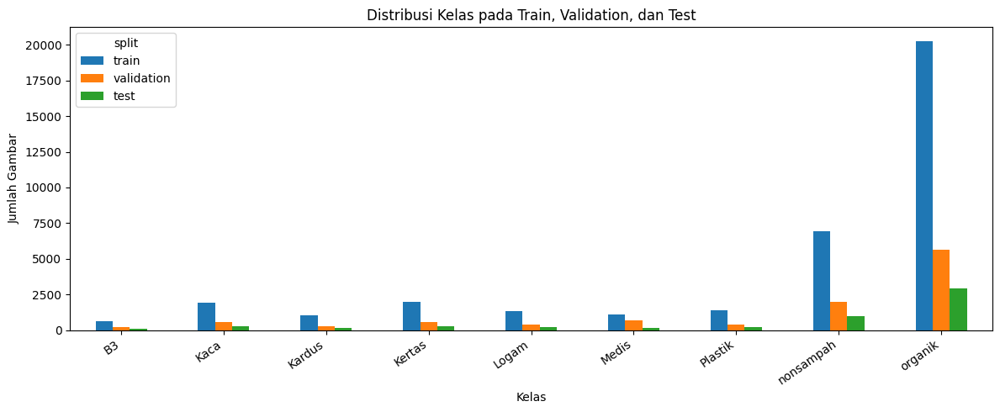

Grafik distribusi split: /content/drive/MyDrive/REKLE_Rebuild/split_class_distribution.png


In [32]:
# CELL 11 — Visualisasi distribusi kelas pada setiap split

class_names = CLASS_NAMES_FIXED.copy()

split_plot = split_summary[class_names].T

ax = split_plot.plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_title("Distribusi Kelas pada Train, Validation, dan Test")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah Gambar")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

split_plot_path = os.path.join(
    DRIVE_DIR, "split_class_distribution.png"
)

plt.savefig(split_plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Grafik distribusi split:", split_plot_path)


In [33]:
# CELL 12 — Audit manifest dan grup setelah split

assert split_manifest["path"].is_unique, (
    "Path gambar muncul lebih dari satu kali pada manifest."
)

group_overlap_check = {}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    ga = set(
        split_manifest.loc[
            split_manifest["split"] == a, "group_id"
        ]
    )
    gb = set(
        split_manifest.loc[
            split_manifest["split"] == b, "group_id"
        ]
    )

    group_overlap_check[f"{a}-{b}"] = len(ga & gb)

print("Jumlah grup overlap:", group_overlap_check)

assert all(
    value == 0 for value in group_overlap_check.values()
), "Ditemukan grup yang melintasi split."

print("Audit split lulus: tidak ada grup yang melintasi split.")

split_audit_path = os.path.join(
    DRIVE_DIR, "split_group_overlap_audit.csv"
)

pd.DataFrame([
    {"perbandingan": key, "jumlah_grup_overlap": value}
    for key, value in group_overlap_check.items()
]).to_csv(split_audit_path, index=False)

print("Laporan audit split:", split_audit_path)


Jumlah grup overlap: {'train-validation': 0, 'train-test': 0, 'validation-test': 0}
Audit split lulus: tidak ada grup yang melintasi split.
Laporan audit split: /content/drive/MyDrive/REKLE_Rebuild/split_group_overlap_audit.csv


## C. Preprocessing, augmentasi, dan data generator
Preprocessing harus konsisten untuk training, evaluasi Keras, TFLite, dan fungsi inferensi. Model menggunakan fungsi preprocessing masing-masing dari Keras Applications.

In [34]:
# CELL 13 — Class weight berdasarkan data train
train_labels = split_manifest.loc[split_manifest.split == "train", "label_id"].to_numpy()
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=train_labels
)
class_weight_dict = {int(i): float(w) for i, w in enumerate(class_weights)}
print({class_names[i]: round(class_weight_dict[i], 4) for i in range(len(class_names))})

{'B3': 6.462, 'Kaca': 2.1147, 'Kardus': 3.9476, 'Kertas': 2.0715, 'Logam': 3.1264, 'Medis': 3.633, 'Plastik': 2.9195, 'nonsampah': 0.5836, 'organik': 0.2006}


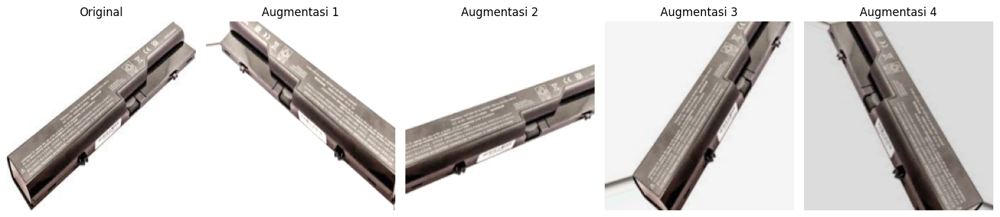

In [35]:
# CELL 14 — Visualisasi contoh augmentasi
augmentation_preview = ImageDataGenerator(
    rotation_range=25,
    zoom_range=0.20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)
sample_class = class_names[0]
sample_files = [
    p for p in (Path(train_dir) / sample_class).iterdir()
    if p.suffix.lower() in VALID_EXT
]
if sample_files:
    with Image.open(sample_files[0]) as im:
        sample = np.asarray(im.convert("RGB").resize(CFG["img_size"], Image.Resampling.BILINEAR))
    batch = np.expand_dims(sample, 0)
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    axes[0].imshow(sample); axes[0].set_title("Original")
    for i, ax in enumerate(axes[1:]):
        aug = next(augmentation_preview.flow(batch, batch_size=1, shuffle=False, seed=SEED + i))[0]
        ax.imshow(np.clip(aug, 0, 255).astype(np.uint8)); ax.set_title(f"Augmentasi {i+1}")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    plt.savefig("augmentation_examples.png", dpi=160)
    plt.show()

In [36]:
# CELL 15 — Buat generator untuk kedua model
def make_generators(preprocess_fn):
    common = {
        "target_size": CFG["img_size"],
        "batch_size": CFG["batch_size"],
        "class_mode": "categorical",
        "classes": class_names,
        "interpolation": "bilinear"
    }
    train_generator = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        rotation_range=25,
        zoom_range=0.20,
        width_shift_range=0.10,
        height_shift_range=0.10,
        horizontal_flip=True,
        brightness_range=[0.8, 1.2]
    ).flow_from_directory(
        train_dir, shuffle=True, seed=SEED, **common
    )
    val_generator = ImageDataGenerator(
        preprocessing_function=preprocess_fn
    ).flow_from_directory(
        val_dir, shuffle=False, **common
    )
    test_generator = ImageDataGenerator(
        preprocessing_function=preprocess_fn
    ).flow_from_directory(
        test_dir, shuffle=False, **common
    )
    return train_generator, val_generator, test_generator

GENERATORS = {
    name: make_generators(spec["preprocess"])
    for name, spec in MODELS.items()
}
y_true = GENERATORS["MobileNetV2"][2].classes.copy()
test_paths = np.asarray(GENERATORS["MobileNetV2"][2].filepaths)
N_TEST = len(y_true)

assert list(GENERATORS["MobileNetV2"][2].filepaths) == list(GENERATORS["ResNet-50"][2].filepaths)
assert np.array_equal(
    GENERATORS["MobileNetV2"][2].classes,
    GENERATORS["ResNet-50"][2].classes
)
print("Jumlah data train:", GENERATORS["MobileNetV2"][0].samples)
print("Jumlah data validation:", GENERATORS["MobileNetV2"][1].samples)
print("Jumlah data test:", N_TEST)

Found 36523 images belonging to 9 classes.
Found 10530 images belonging to 9 classes.
Found 5218 images belonging to 9 classes.
Found 36523 images belonging to 9 classes.
Found 10530 images belonging to 9 classes.
Found 5218 images belonging to 9 classes.
Jumlah data train: 36523
Jumlah data validation: 10530
Jumlah data test: 5218


## D. Arsitektur dan pelatihan transfer learning dua tahap
Tahap pertama melatih classifier dengan backbone beku. Tahap kedua membuka fraksi layer terakhir backbone untuk fine-tuning. Batch Normalization pada backbone tetap dibekukan.

In [37]:
# CELL 16 — Fungsi pembentukan model dan konfigurasi training
def build_transfer_model(model_name):
    backbone = MODELS[model_name]["app"](
        input_shape=(*CFG["img_size"], 3),
        include_top=False,
        weights="imagenet"
    )
    backbone.trainable = False

    inputs = tf.keras.Input(shape=(*CFG["img_size"], 3))
    x = backbone(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.BatchNormalization(name="classifier_batch_norm")(x)
    x = layers.Dropout(CFG["dropout"], name="classifier_dropout")(x)
    outputs = layers.Dense(len(class_names), activation="softmax", name="classifier_output")(x)

    model = models.Model(inputs, outputs, name=model_name.replace("-", "") + "_REKLE")
    return model, backbone

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

def train_two_stages(model_name):
    train_gen, val_gen, _ = GENERATORS[model_name]
    model, backbone = build_transfer_model(model_name)
    prefix = MODELS[model_name]["prefix"]
    ckpt_stage1 = f"{prefix}_stage1_best.keras"
    ckpt_stage2 = f"{prefix}_stage2_best.keras"

    # Stage 1: feature extraction
    compile_model(model, CFG["stage1_lr"])
    history1 = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=CFG["stage1_max_epochs"],
        class_weight=class_weight_dict,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=CFG["stage1_patience"],
                restore_best_weights=True,
                verbose=1
            ),
            ReduceLROnPlateau(
                monitor="val_loss",
                patience=CFG["reduce_lr_patience"],
                factor=CFG["reduce_lr_factor"],
                verbose=1
            ),
            ModelCheckpoint(
                ckpt_stage1, monitor="val_loss",
                save_best_only=True, verbose=0
            )
        ],
        verbose=2
    )

    # Stage 2: fine-tuning layer backbone terakhir; BatchNorm backbone tetap beku.
    backbone.trainable = True
    unfreeze_count = max(1, int(len(backbone.layers) * CFG["fine_tune_fraction"]))
    for layer in backbone.layers[:-unfreeze_count]:
        layer.trainable = False
    for layer in backbone.layers[-unfreeze_count:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)

    print(
        f"{model_name}: total layer backbone={len(backbone.layers)}, "
        f"fraksi fine-tuning={CFG['fine_tune_fraction']:.0%}, "
        f"layer terakhir yang ditinjau={unfreeze_count}"
    )

    compile_model(model, CFG["stage2_lr"])
    history2 = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=CFG["stage2_max_epochs"],
        class_weight=class_weight_dict,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=CFG["stage2_patience"],
                restore_best_weights=True,
                verbose=1
            ),
            ReduceLROnPlateau(
                monitor="val_loss",
                patience=CFG["reduce_lr_patience"],
                factor=CFG["reduce_lr_factor"],
                verbose=1
            ),
            ModelCheckpoint(
                ckpt_stage2, monitor="val_loss",
                save_best_only=True, verbose=0
            )
        ],
        verbose=2
    )

    # Bandingkan checkpoint stage 1 dan stage 2 hanya berdasarkan validation loss.
    stage1_best = float(np.min(history1.history["val_loss"]))
    stage2_best = float(np.min(history2.history["val_loss"]))
    selected_checkpoint = ckpt_stage1 if stage1_best <= stage2_best else ckpt_stage2
    selected_stage = "stage1" if stage1_best <= stage2_best else "stage2"
    selected_model = tf.keras.models.load_model(selected_checkpoint)

    history = {}
    for key in history1.history:
        history[key] = (
            list(history1.history[key]) +
            list(history2.history.get(key, []))
        )

    pd.DataFrame(history).to_csv(f"history_{prefix}.csv", index=False)
    checkpoint_info = {
        "model": model_name,
        "stage1_best_val_loss": stage1_best,
        "stage2_best_val_loss": stage2_best,
        "selected_stage": selected_stage,
        "selected_checkpoint": selected_checkpoint,
        "stage1_epochs_run": len(history1.history["loss"]),
        "stage2_epochs_run": len(history2.history["loss"])
    }
    return selected_model, history, checkpoint_info

In [ ]:
# CELL 17 — Training MobileNetV2
mobilenet_model, mobilenet_history, mobilenet_checkpoint = train_two_stages("MobileNetV2")
print(json.dumps(mobilenet_checkpoint, indent=2))

In [41]:
# CELL 18 — Training ResNet-50
resnet_model, resnet_history, resnet_checkpoint = train_two_stages("ResNet-50")
print(json.dumps(resnet_checkpoint, indent=2))

Epoch 1/15
1142/1142 - 218s - 191ms/step - accuracy: 0.8144 - loss: 0.6587 - val_accuracy: 0.9129 - val_loss: 0.3068 - learning_rate: 0.0010
Epoch 2/15
1142/1142 - 215s - 188ms/step - accuracy: 0.8745 - loss: 0.4612 - val_accuracy: 0.9194 - val_loss: 0.2772 - learning_rate: 0.0010
Epoch 3/15
1142/1142 - 215s - 188ms/step - accuracy: 0.8815 - loss: 0.4297 - val_accuracy: 0.9176 - val_loss: 0.2924 - learning_rate: 0.0010
Epoch 4/15
1142/1142 - 213s - 187ms/step - accuracy: 0.8863 - loss: 0.4115 - val_accuracy: 0.9163 - val_loss: 0.3096 - learning_rate: 0.0010
Epoch 5/15

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1142/1142 - 213s - 186ms/step - accuracy: 0.8882 - loss: 0.4083 - val_accuracy: 0.9208 - val_loss: 0.2785 - learning_rate: 0.0010
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
ResNet-50: total layer backbone=175, fraksi fine-tuning=20%, layer terakhir yang ditinjau=35
Epoch 1/30
1142/1142 - 223s - 195ms/step -

In [42]:
# CELL 19 — Daftar model terlatih, checkpoint, dan histori
TRAINED = {
    "MobileNetV2": mobilenet_model,
    "ResNet-50": resnet_model
}
HISTORIES = {
    "MobileNetV2": mobilenet_history,
    "ResNet-50": resnet_history
}
CHECKPOINTS = {
    "MobileNetV2": mobilenet_checkpoint,
    "ResNet-50": resnet_checkpoint
}
for name in TRAINED:
    print(name, "parameters:", TRAINED[name].count_params(),
          "| checkpoint terpilih:", CHECKPOINTS[name]["selected_checkpoint"])

MobileNetV2 parameters: 2274633 | checkpoint terpilih: mobilenet_stage2_best.keras
ResNet-50 parameters: 23614345 | checkpoint terpilih: resnet_stage2_best.keras


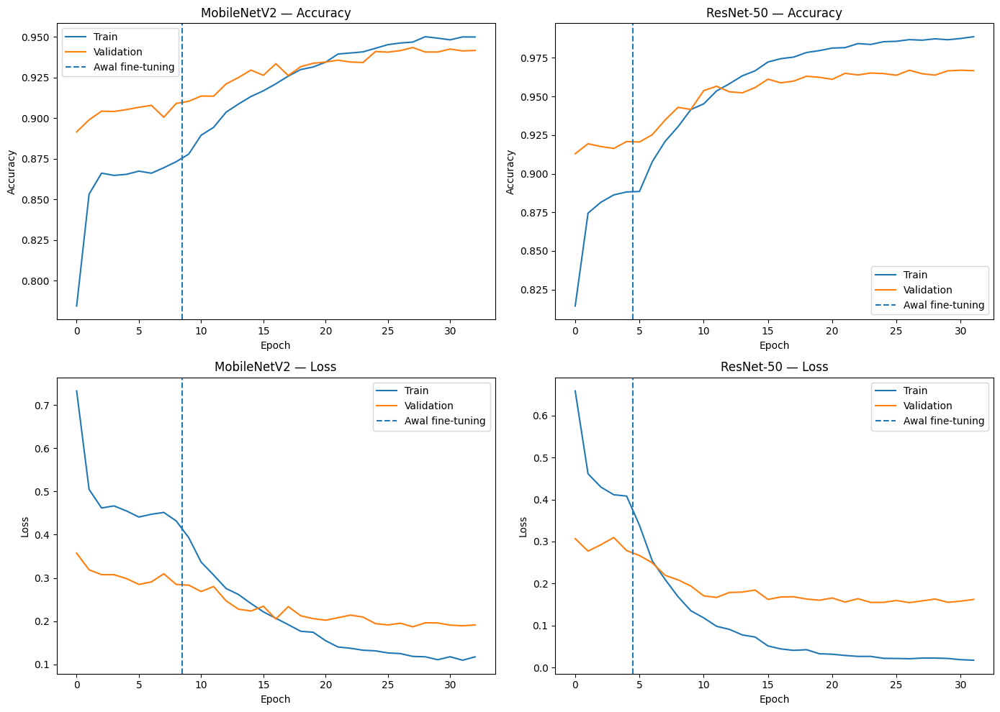

In [43]:
# CELL 20 — Visualisasi kurva training dan validation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, name in enumerate(["MobileNetV2", "ResNet-50"]):
    hist = HISTORIES[name]
    stage1_epochs = CHECKPOINTS[name]["stage1_epochs_run"]

    axes[0, col].plot(hist["accuracy"], label="Train")
    axes[0, col].plot(hist["val_accuracy"], label="Validation")
    axes[0, col].axvline(stage1_epochs - 0.5, linestyle="--", label="Awal fine-tuning")
    axes[0, col].set_title(f"{name} — Accuracy")
    axes[0, col].set_xlabel("Epoch"); axes[0, col].set_ylabel("Accuracy")
    axes[0, col].legend()

    axes[1, col].plot(hist["loss"], label="Train")
    axes[1, col].plot(hist["val_loss"], label="Validation")
    axes[1, col].axvline(stage1_epochs - 0.5, linestyle="--", label="Awal fine-tuning")
    axes[1, col].set_title(f"{name} — Loss")
    axes[1, col].set_xlabel("Epoch"); axes[1, col].set_ylabel("Loss")
    axes[1, col].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=160)
plt.show()

In [44]:
# CELL 21 — Audit overfitting: train tanpa augmentasi, validation, dan test
overfit_rows = []
for name in TRAINED:
    prep = MODELS[name]["preprocess"]
    clean_train_gen = ImageDataGenerator(
        preprocessing_function=prep
    ).flow_from_directory(
        train_dir,
        target_size=CFG["img_size"],
        batch_size=CFG["batch_size"],
        class_mode="categorical",
        classes=class_names,
        shuffle=False,
        interpolation="bilinear"
    )

    metrics = {}
    for split_name, generator in [
        ("train_no_aug", clean_train_gen),
        ("validation", GENERATORS[name][1]),
        ("test", GENERATORS[name][2])
    ]:
        generator.reset()
        loss, acc = TRAINED[name].evaluate(generator, verbose=0)
        metrics[split_name] = {"loss": float(loss), "accuracy": float(acc)}

    overfit_rows.append({
        "Model": name,
        "Train_accuracy_no_augmentation": metrics["train_no_aug"]["accuracy"],
        "Validation_accuracy": metrics["validation"]["accuracy"],
        "Test_accuracy": metrics["test"]["accuracy"],
        "Train_validation_gap": metrics["train_no_aug"]["accuracy"] - metrics["validation"]["accuracy"],
        "Validation_test_gap": metrics["validation"]["accuracy"] - metrics["test"]["accuracy"],
        "Train_loss": metrics["train_no_aug"]["loss"],
        "Validation_loss": metrics["validation"]["loss"],
        "Test_loss": metrics["test"]["loss"]
    })

overfit_df = pd.DataFrame(overfit_rows).round(4)
display(overfit_df)
overfit_df.to_csv("overfitting_audit.csv", index=False)

Found 36523 images belonging to 9 classes.
Found 36523 images belonging to 9 classes.


,Model,Train_accuracy_no_augmentation,Validation_accuracy,Test_accuracy,Train_validation_gap,Validation_test_gap,Train_loss,Validation_loss,Test_loss
0,MobileNetV2,0.9730,0.9434,0.9423,0.0296,0.0011,0.0886,0.1870,0.1935
1,ResNet-50,0.9963,0.9670,0.9638,0.0294,0.0032,0.0115,0.1545,0.1572


## E. Evaluasi pada test set dan analisis kesalahan
Test set hanya digunakan pada tahap evaluasi akhir. Kedua model dievaluasi pada file dan urutan label yang sama.

In [45]:
# CELL 22 — Prediksi test set kedua model
PREDICTIONS, PROBABILITIES = {}, {}
for name in TRAINED:
    test_generator = GENERATORS[name][2]
    test_generator.reset()
    probabilities = TRAINED[name].predict(test_generator, verbose=1)
    PROBABILITIES[name] = probabilities
    PREDICTIONS[name] = probabilities.argmax(axis=1)

assert np.array_equal(
    GENERATORS["MobileNetV2"][2].classes,
    GENERATORS["ResNet-50"][2].classes
), "Urutan label test kedua model berbeda."

y_true = GENERATORS["MobileNetV2"][2].classes.copy()
test_paths = np.asarray(GENERATORS["MobileNetV2"][2].filepaths)
assert len(y_true) == len(test_paths) == len(PREDICTIONS["MobileNetV2"])
print("Evaluasi test set selesai. Jumlah sampel:", len(y_true))

164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step
164/164 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step
Evaluasi test set selesai. Jumlah sampel: 5218


### Evaluasi baseline lama pada test set baru (opsional, tetapi diperlukan untuk McNemar berpasangan)

Agar uji McNemar membandingkan baseline lama dengan model hasil rebuild secara sah, checkpoint baseline lama harus dijalankan ulang pada **test set rebuild yang sama**. Letakkan checkpoint lama dan `class_names.json` dari eksperimen lama di folder `baseline_old` pada Google Drive. Jika checkpoint tidak tersedia, perbandingan historis hanya bersifat deskriptif dan McNemar terhadap baseline lama tidak boleh dihitung.


In [46]:
# CELL 22A — Prediksi baseline lama pada test set rebuild yang sama (jika checkpoint tersedia)
BASELINE_DIR = os.path.join(DRIVE_DIR, "baseline_old")
BASELINE_PATHS = {
    "MobileNetV2": os.path.join(BASELINE_DIR, "baseline_mobilenet.keras"),
    "ResNet-50": os.path.join(BASELINE_DIR, "baseline_resnet.keras")
}
BASELINE_CLASS_NAMES_PATH = os.path.join(BASELINE_DIR, "class_names.json")
BASELINE_MODELS, BASELINE_PREDICTIONS, BASELINE_COMPARISON = {}, {}, {}

if all(os.path.isfile(p) for p in BASELINE_PATHS.values()) and os.path.isfile(BASELINE_CLASS_NAMES_PATH):
    with open(BASELINE_CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
        baseline_class_names = json.load(f)
    if set(baseline_class_names) != set(class_names):
        raise ValueError(
            "Daftar kelas checkpoint baseline berbeda dari eksperimen rebuild. "
            "Pemetaan output model harus diverifikasi sebelum evaluasi."
        )
    column_order = [baseline_class_names.index(c) for c in class_names]

    for model_name, model_path in BASELINE_PATHS.items():
        old_model = tf.keras.models.load_model(model_path)
        old_val_gen = ImageDataGenerator(
            preprocessing_function=MODELS[model_name]["preprocess"]
        ).flow_from_directory(
            test_dir, target_size=CFG["img_size"], batch_size=CFG["batch_size"],
            class_mode="categorical", classes=class_names,
            shuffle=False, interpolation="bilinear"
        )
        old_prob = old_model.predict(old_val_gen, verbose=1)
        old_prob = old_prob[:, column_order]
        old_pred = old_prob.argmax(axis=1)
        BASELINE_MODELS[model_name] = old_model
        BASELINE_PREDICTIONS[model_name] = old_pred

        discord_new_correct = int(np.sum((PREDICTIONS[model_name] == y_true) & (old_pred != y_true)))
        discord_old_correct = int(np.sum((PREDICTIONS[model_name] != y_true) & (old_pred == y_true)))
        n_discordant = discord_new_correct + discord_old_correct
        p_exact = float(binomtest(
            min(discord_new_correct, discord_old_correct), n=n_discordant,
            p=0.5, alternative="two-sided"
        ).pvalue) if n_discordant else 1.0
        BASELINE_COMPARISON[model_name] = {
            "new_accuracy": float(accuracy_score(y_true, PREDICTIONS[model_name])),
            "old_accuracy_on_same_test": float(accuracy_score(y_true, old_pred)),
            "new_macro_f1": float(f1_score(y_true, PREDICTIONS[model_name], average="macro", zero_division=0)),
            "old_macro_f1_on_same_test": float(f1_score(y_true, old_pred, average="macro", zero_division=0)),
            "new_correct_old_wrong": discord_new_correct,
            "new_wrong_old_correct": discord_old_correct,
            "mcnemar_exact_p": p_exact
        }
    baseline_comparison_df = pd.DataFrame(BASELINE_COMPARISON).T
    display(baseline_comparison_df.round(4))
    baseline_comparison_df.to_csv("baseline_old_vs_rebuild_same_test.csv")
else:
    print("Checkpoint baseline lama belum ditemukan.")
    print("Simpan baseline_mobilenet.keras, baseline_resnet.keras, dan class_names.json ke:", BASELINE_DIR)
    print("Tanpa checkpoint lama, McNemar hanya dilakukan antara MobileNetV2 dan ResNet50 hasil rebuild pada test set yang sama.")


Checkpoint baseline lama belum ditemukan.
Simpan baseline_mobilenet.keras, baseline_resnet.keras, dan class_names.json ke: /content/drive/MyDrive/REKLE_Rebuild/baseline_old
Tanpa checkpoint lama, McNemar hanya dilakukan antara MobileNetV2 dan ResNet50 hasil rebuild pada test set yang sama.


In [47]:
# CELL 23 — Classification report, metrik macro/weighted, dan per-class metrics
SUMMARY = {}
PER_CLASS = {}

for name in TRAINED:
    y_pred = PREDICTIONS[name]
    print(f"\n===== CLASSIFICATION REPORT: {name} =====")
    print(classification_report(
        y_true, y_pred, labels=np.arange(len(class_names)),
        target_names=class_names, digits=4, zero_division=0
    ))

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(class_names)), zero_division=0
    )
    PER_CLASS[name] = pd.DataFrame({
        "Kelas": class_names,
        "Support": support,
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1
    })

    SUMMARY[name] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0
        )[0],
        "macro_recall": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_precision": precision_recall_fscore_support(
            y_true, y_pred, average="weighted", zero_division=0
        )[0],
        "weighted_recall": precision_recall_fscore_support(
            y_true, y_pred, average="weighted", zero_division=0
        )[1],
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "minimum_class_recall": float(np.min(recall))
    }

summary_df = pd.DataFrame(SUMMARY).T
display(summary_df.round(4))
summary_df.to_csv("test_metrics_summary.csv")
per_class_comparison = PER_CLASS["MobileNetV2"].merge(
    PER_CLASS["ResNet-50"],
    on=["Kelas", "Support"],
    suffixes=("_MobileNetV2", "_ResNet50")
)
display(per_class_comparison.round(4))
per_class_comparison.to_csv("per_class_comparison.csv", index=False)


===== CLASSIFICATION REPORT: MobileNetV2 =====
              precision    recall  f1-score   support

          B3     0.8901    0.9529    0.9205        85
        Kaca     0.8531    0.8841    0.8683       276
      Kardus     0.8129    0.8690    0.8400       145
      Kertas     0.7257    0.8881    0.7987       277
       Logam     0.7990    0.8978    0.8456       186
       Medis     0.9817    1.0000    0.9908       161
     Plastik     0.7593    0.8410    0.7981       195
   nonsampah     0.9939    0.9889    0.9914       995
     organik     0.9913    0.9469    0.9686      2898

    accuracy                         0.9423      5218
   macro avg     0.8675    0.9187    0.8913      5218
weighted avg     0.9480    0.9423    0.9442      5218


===== CLASSIFICATION REPORT: ResNet-50 =====
              precision    recall  f1-score   support

          B3     0.9032    0.9882    0.9438        85
        Kaca     0.9014    0.9275    0.9143       276
      Kardus     0.9071    0.8759    0

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,minimum_class_recall
MobileNetV2,0.9423,0.8675,0.9187,0.8913,0.9480,0.9423,0.9442,0.8410
ResNet-50,0.9638,0.9186,0.9445,0.9304,0.9662,0.9638,0.9645,0.8759


,Kelas,Support,Precision_MobileNetV2,Recall_MobileNetV2,F1_score_MobileNetV2,Precision_ResNet50,Recall_ResNet50,F1_score_ResNet50
0,B3,85,0.8901,0.9529,0.9205,0.9032,0.9882,0.9438
1,Kaca,276,0.8531,0.8841,0.8683,0.9014,0.9275,0.9143
2,Kardus,145,0.8129,0.8690,0.8400,0.9071,0.8759,0.8912
3,Kertas,277,0.7257,0.8881,0.7987,0.7885,0.9422,0.8586
4,Logam,186,0.7990,0.8978,0.8456,0.8866,0.9247,0.9053
5,Medis,161,0.9817,1.0000,0.9908,1.0000,1.0000,1.0000
6,Plastik,195,0.7593,0.8410,0.7981,0.8906,0.8769,0.8837
7,nonsampah,995,0.9939,0.9889,0.9914,0.9980,0.9970,0.9975
8,organik,2898,0.9913,0.9469,0.9686,0.9915,0.9679,0.9796


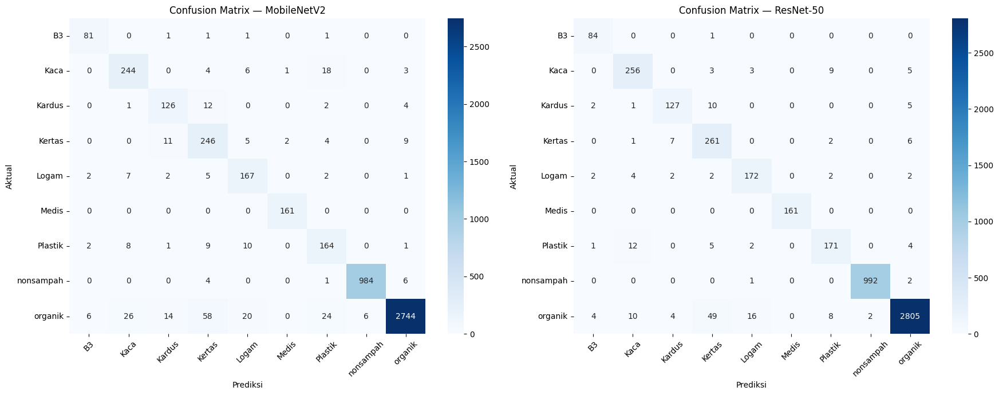

In [48]:
# CELL 24 — Confusion matrix mentah
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, name in zip(axes, ["MobileNetV2", "ResNet-50"]):
    cm = confusion_matrix(y_true, PREDICTIONS[name], labels=np.arange(len(class_names)))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=160)
plt.show()

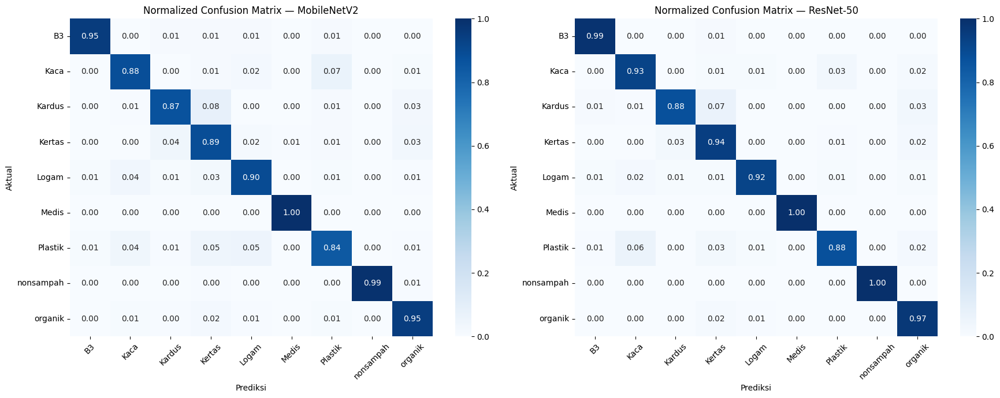

In [49]:
# CELL 25 — Normalized confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, name in zip(axes, ["MobileNetV2", "ResNet-50"]):
    cm_norm = confusion_matrix(
        y_true, PREDICTIONS[name],
        labels=np.arange(len(class_names)),
        normalize="true"
    )
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues",
        vmin=0, vmax=1,
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(f"Normalized Confusion Matrix — {name}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig("confusion_normalized.png", dpi=160)
plt.show()

In [50]:
# CELL 26 — Analisis pasangan kelas yang paling sering tertukar
def top_confusions(y_pred, top_k=10):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    rows = []
    for actual_id in range(len(class_names)):
        for predicted_id in range(len(class_names)):
            if actual_id != predicted_id and cm[actual_id, predicted_id] > 0:
                support = cm[actual_id].sum()
                rows.append({
                    "Aktual": class_names[actual_id],
                    "Prediksi": class_names[predicted_id],
                    "Jumlah": int(cm[actual_id, predicted_id]),
                    "Persentase_dari_kelas_aktual": (
                        100 * cm[actual_id, predicted_id] / support if support else 0
                    )
                })
    return pd.DataFrame(rows).sort_values(
        ["Jumlah", "Persentase_dari_kelas_aktual"], ascending=False
    ).head(top_k)

for name in TRAINED:
    print(f"\nKesalahan terbanyak — {name}")
    display(top_confusions(PREDICTIONS[name], top_k=10))
# Narasi untuk naskah harus disusun dari tabel top_confusion aktual setelah training;
# jangan menyimpulkan penyebab visual (warna/bentuk/tekstur) tanpa inspeksi sampel gambarnya.



Kesalahan terbanyak — MobileNetV2


,Aktual,Prediksi,Jumlah,Persentase_dari_kelas_aktual
36,organik,Kertas,58,2.001380
34,organik,Kaca,26,0.897170
38,organik,Plastik,24,0.828157
37,organik,Logam,20,0.690131
7,Kaca,Plastik,18,6.521739
35,organik,Kardus,14,0.483092
10,Kardus,Kertas,12,8.275862
13,Kertas,Kardus,11,3.971119
28,Plastik,Logam,10,5.128205
27,Plastik,Kertas,9,4.615385



Kesalahan terbanyak — ResNet-50


,Aktual,Prediksi,Jumlah,Persentase_dari_kelas_aktual
29,organik,Kertas,49,1.690821
30,organik,Logam,16,0.552105
20,Plastik,Kaca,12,6.153846
7,Kardus,Kertas,10,6.896552
27,organik,Kaca,10,0.345066
3,Kaca,Plastik,9,3.260870
31,organik,Plastik,8,0.276052
10,Kertas,Kardus,7,2.527076
12,Kertas,organik,6,2.166065
8,Kardus,organik,5,3.448276


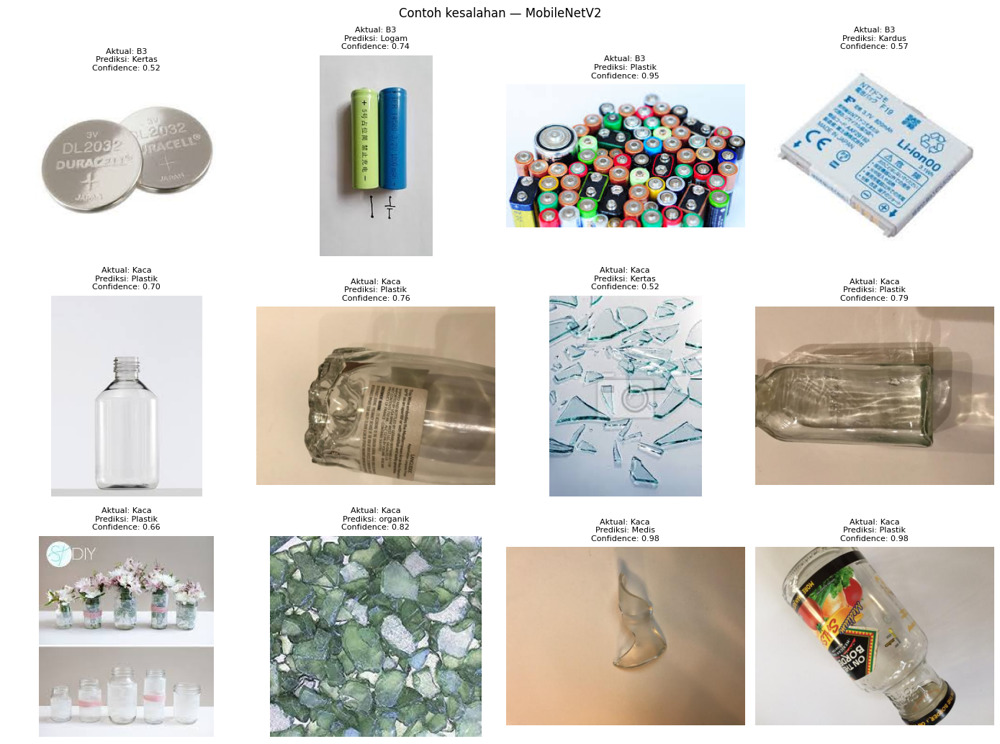

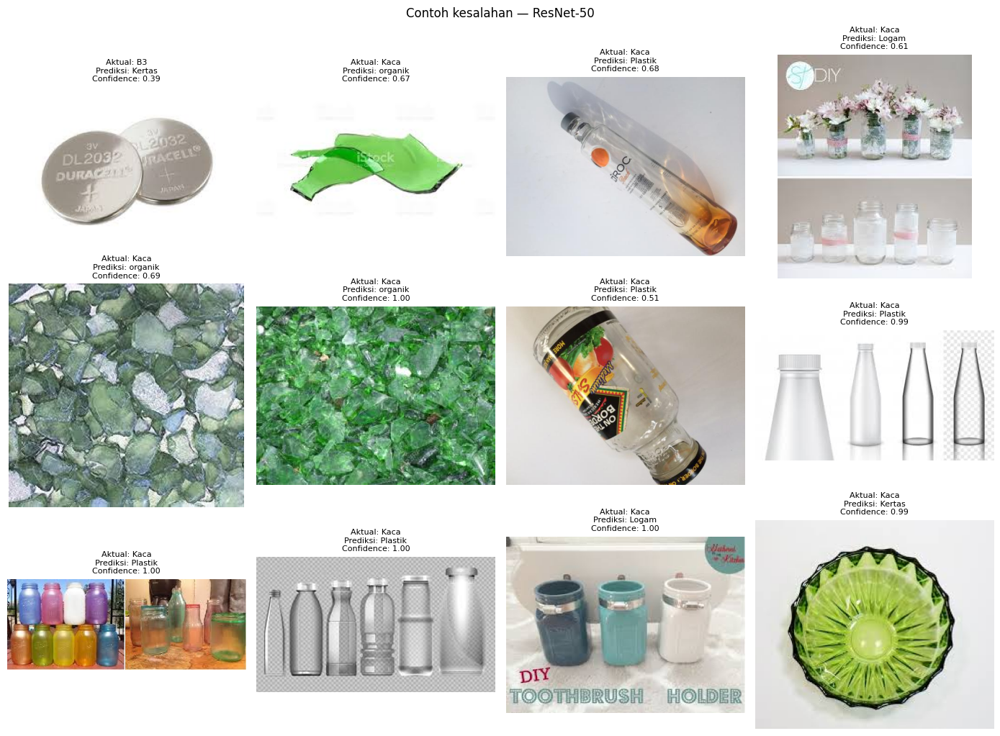

Interpretasi penyebab kesalahan harus dilakukan dengan memeriksa gambar aktual, bukan ditebak dari label saja.


In [51]:
# CELL 27 — Visualisasi contoh kesalahan klasifikasi
for name in TRAINED:
    errors = np.where(PREDICTIONS[name] != y_true)[0]
    if len(errors) == 0:
        print(name, ": tidak ada kesalahan pada test set.")
        continue

    selected = errors[:12]
    ncols = 4
    nrows = math.ceil(len(selected) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, selected):
        with Image.open(test_paths[idx]) as im:
            ax.imshow(im.convert("RGB"))
        actual = class_names[int(y_true[idx])]
        predicted = class_names[int(PREDICTIONS[name][idx])]
        confidence = float(np.max(PROBABILITIES[name][idx]))
        ax.set_title(
            f"Aktual: {actual}\nPrediksi: {predicted}\nConfidence: {confidence:.2f}",
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.suptitle(f"Contoh kesalahan — {name}")
    plt.tight_layout()
    plt.savefig(f"error_examples_{name.replace('-', '_')}.png", dpi=160)
    plt.show()

print("Interpretasi penyebab kesalahan harus dilakukan dengan memeriksa gambar aktual, bukan ditebak dari label saja.")

## F. Uji statistik dan interval kepercayaan

**Uji McNemar berpasangan.** Hipotesis nol (H0): pada sampel uji yang sama, peluang MobileNetV2 benar sementara ResNet50 salah sama dengan peluang ResNet50 benar sementara MobileNetV2 salah. Hipotesis alternatif (H1): kedua peluang discordant tersebut berbeda. Uji ini dipilih karena prediksi kedua model berasal dari citra test yang identik; observasi benar/salah antar-model berpasangan, bukan dua sampel independen. Gunakan uji binomial eksak dua sisi pada pasangan discordant, dengan α = 0,05. Jika p-value < α, terdapat bukti statistik perbedaan pola kesalahan; p-value bukan ukuran besar manfaat praktis. Laporkan juga selisih akurasi, interval kepercayaan, dan metrik per kelas.

**Bootstrap.** Jika gambar-gambar dalam satu grup duplikat/near-duplicate saling berkorelasi, interval kepercayaan sebaiknya diestimasi dengan resampling pada tingkat grup, bukan hanya resampling gambar individual. Hasil bootstrap per-gambar dapat dilaporkan sebagai analisis tambahan, dengan keterbatasannya dijelaskan.


Catatan: McNemar standar pada tingkat gambar tetap mengasumsikan pasangan antar-gambar independen. Karena itu hasilnya harus dibaca bersama audit grup dan bootstrap berpasangan tingkat grup; bila jumlah grup uji cukup, analisis sensitivitas berbasis grup juga dapat dilaporkan.


## F. Uji statistik dan interval kepercayaan
McNemar digunakan karena dua model menghasilkan prediksi pada sampel test yang sama. P-value menunjukkan bukti statistik, bukan besarnya manfaat praktis.

Catatan: McNemar standar pada tingkat gambar tetap mengasumsikan pasangan antar-gambar independen. Karena itu hasilnya harus dibaca bersama audit grup dan bootstrap berpasangan tingkat grup; bila jumlah grup uji cukup, analisis sensitivitas berbasis grup juga dapat dilaporkan.


In [67]:

# ============================================================
# CELL 28 — McNemar Exact Test dan Bootstrap Paired Confidence Interval
# ============================================================

from pathlib import Path
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# 1. MCNEMAR EXACT TEST
# ------------------------------------------------------------

alpha = CFG["alpha"]

correct_m = (PREDICTIONS["MobileNetV2"] == y_true)
correct_r = (PREDICTIONS["ResNet-50"] == y_true)

n_both_correct = int((correct_m & correct_r).sum())

n_m_correct_r_wrong = int(
    (correct_m & ~correct_r).sum()
)

n_m_wrong_r_correct = int(
    (~correct_m & correct_r).sum()
)

n_both_wrong = int(
    (~correct_m & ~correct_r).sum()
)

discordant = (
    n_m_correct_r_wrong +
    n_m_wrong_r_correct
)

p_mcnemar_exact = (
    binomtest(
        min(n_m_correct_r_wrong, n_m_wrong_r_correct),
        discordant,
        0.5
    ).pvalue
    if discordant > 0 else 1.0
)

print("=" * 65)
print("MCNEMAR EXACT TEST")
print("=" * 65)

display(pd.DataFrame(
    [
        [n_both_correct, n_m_correct_r_wrong],
        [n_m_wrong_r_correct, n_both_wrong]
    ],
    index=["MobileNet benar", "MobileNet salah"],
    columns=["ResNet benar", "ResNet salah"]
))

print("Jumlah pasangan diskordan:", discordant)
print(f"McNemar exact p-value: {p_mcnemar_exact:.10g}")
print("Alpha:", alpha)

print(
    "Interpretasi:",
    "Perbedaan signifikan secara statistik"
    if p_mcnemar_exact < alpha
    else "Belum terdapat bukti perbedaan signifikan secara statistik"
)


# ------------------------------------------------------------
# 2. MAPPING GAMBAR KE GROUP NEAR-DUPLICATE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MAPPING NEAR-DUPLICATE GROUP")
print("=" * 65)

# Normalisasi path menggunakan nama kelas + nama file
def get_image_key(path):
    p = Path(str(path))
    return f"{p.parent.name}/{p.name}"


# Pastikan manifest tersedia
required_columns = {"path", "group_id"}

if not required_columns.issubset(split_manifest.columns):
    raise ValueError(
        "split_manifest harus memiliki kolom path dan group_id."
    )

# Buat key gambar dari manifest
manifest_keys = split_manifest["path"].apply(get_image_key)

manifest_mapping = pd.DataFrame({
    "image_key": manifest_keys,
    "group_id": split_manifest["group_id"]
})

# Periksa apakah ada gambar dengan group_id berbeda
duplicate_groups = (
    manifest_mapping.groupby("image_key")["group_id"].nunique()
)

conflicting_keys = duplicate_groups[
    duplicate_groups > 1
]

if len(conflicting_keys) > 0:
    raise ValueError(
        f"Ditemukan {len(conflicting_keys)} gambar "
        "dengan group_id berbeda dalam manifest."
    )

# Hilangkan mapping identik yang berulang
manifest_mapping = manifest_mapping.drop_duplicates(
    subset=["image_key"]
)

# Dictionary path -> group_id
path_to_group = dict(zip(
    manifest_mapping["image_key"],
    manifest_mapping["group_id"]
))

# Normalisasi test paths
test_keys = [
    get_image_key(p)
    for p in test_paths
]

# Periksa gambar yang tidak ditemukan
missing_keys = [
    key for key in test_keys
    if key not in path_to_group
]

if missing_keys:
    raise ValueError(
        f"{len(missing_keys)} gambar test tidak ditemukan "
        f"dalam manifest. Contoh: {missing_keys[:5]}"
    )

# Ambil group_id seluruh gambar test
test_group_ids = np.asarray([
    path_to_group[key]
    for key in test_keys
])

# Validasi dimensi
if len(test_group_ids) != len(y_true):
    raise ValueError(
        "Jumlah test_group_ids tidak sama dengan jumlah y_true."
    )

# Kelompokkan group berdasarkan kelas
class_group_ids = {
    k: np.unique(test_group_ids[y_true == k])
    for k in range(len(class_names))
}

print("Mapping berhasil!")
print("Total gambar test:", len(test_group_ids))
print("Total grup near-duplicate:", len(np.unique(test_group_ids)))

for k, groups in class_group_ids.items():
    print(f"{class_names[k]}: {len(groups)} grup")


# ------------------------------------------------------------
# 3. VALIDASI GROUP NEAR-DUPLICATE ANTARKELAS
# ------------------------------------------------------------

# Satu group seharusnya tidak tersebar pada beberapa kelas.
group_class_counts = pd.DataFrame({
    "group_id": test_group_ids,
    "class_id": y_true
}).groupby("group_id")["class_id"].nunique()

cross_class_groups = group_class_counts[
    group_class_counts > 1
]

if len(cross_class_groups) > 0:
    raise ValueError(
        f"Ditemukan {len(cross_class_groups)} grup "
        "near-duplicate yang mencakup beberapa kelas. "
        "Perlu peninjauan sebelum bootstrap."
    )

print("Validasi grup antarkelas berhasil.")


# ------------------------------------------------------------
# 4. PAIRED STRATIFIED GROUP BOOTSTRAP
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PAIRED GROUP BOOTSTRAP")
print("=" * 65)

rng = np.random.default_rng(SEED)

B = CFG["bootstrap_iterations"]

accuracy_diffs = np.empty(B, dtype=float)
macro_f1_diffs = np.empty(B, dtype=float)

# Precompute indeks gambar untuk setiap grup
group_to_indices = {
    group_id: np.where(test_group_ids == group_id)[0]
    for group_id in np.unique(test_group_ids)
}

# Sampling dilakukan per kelas pada tingkat grup.
for b in range(B):

    sampled_parts = []

    for k, group_ids_k in class_group_ids.items():

        if len(group_ids_k) == 0:
            continue

        # Sampling grup dengan replacement
        sampled_groups = rng.choice(
            group_ids_k,
            size=len(group_ids_k),
            replace=True
        )

        # Masukkan seluruh gambar dari grup terpilih
        for group_id in sampled_groups:

            sampled_parts.append(
                group_to_indices[group_id]
            )

    sampled = np.concatenate(sampled_parts)

    # Perbandingan accuracy
    accuracy_diffs[b] = (
        accuracy_score(
            y_true[sampled],
            PREDICTIONS["ResNet-50"][sampled]
        )
        -
        accuracy_score(
            y_true[sampled],
            PREDICTIONS["MobileNetV2"][sampled]
        )
    ) * 100

    # Perbandingan macro F1
    macro_f1_diffs[b] = (
        f1_score(
            y_true[sampled],
            PREDICTIONS["ResNet-50"][sampled],
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )
        -
        f1_score(
            y_true[sampled],
            PREDICTIONS["MobileNetV2"][sampled],
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )
    )

    if (b + 1) % max(1, B // 10) == 0:
        print(f"Bootstrap: {b + 1}/{B}")


# ------------------------------------------------------------
# 5. HITUNG SELISIH METRIK DAN 95% CI
# ------------------------------------------------------------

# Accuracy difference: ResNet - MobileNet
accuracy_diff_pp = (
    accuracy_score(
        y_true,
        PREDICTIONS["ResNet-50"]
    )
    -
    accuracy_score(
        y_true,
        PREDICTIONS["MobileNetV2"]
    )
) * 100

acc_ci_low, acc_ci_high = np.percentile(
    accuracy_diffs,
    [2.5, 97.5]
)

# Macro F1 difference: ResNet - MobileNet
f1_diff = (
    SUMMARY["ResNet-50"]["macro_f1"]
    -
    SUMMARY["MobileNetV2"]["macro_f1"]
)

f1_ci_low, f1_ci_high = np.percentile(
    macro_f1_diffs,
    [2.5, 97.5]
)


# ------------------------------------------------------------
# 6. SIMPAN HASIL STATISTIK
# ------------------------------------------------------------

STATISTICS = {
    "mcnemar_exact_p": float(p_mcnemar_exact),

    "mcnemar_discordant_pairs": int(discordant),

    "mcnemar_mobile_net_correct_resnet_wrong":
        int(n_m_correct_r_wrong),

    "mcnemar_resnet_correct_mobile_net_wrong":
        int(n_m_wrong_r_correct),

    "accuracy_difference_pp_resnet_minus_mobilenet":
        float(accuracy_diff_pp),

    "accuracy_difference_95ci_pp": [
        float(acc_ci_low),
        float(acc_ci_high)
    ],

    "macro_f1_difference_resnet_minus_mobilenet":
        float(f1_diff),

    "macro_f1_difference_95ci": [
        float(f1_ci_low),
        float(f1_ci_high)
    ],

    "alpha": float(alpha),

    "bootstrap_iterations": int(B),

    "bootstrap_unit": "duplicate_near_duplicate_group",

    "bootstrap_method": "stratified_paired_group_bootstrap",

    "test_images": int(len(test_group_ids)),

    "test_groups": int(len(np.unique(test_group_ids))),

    "cross_class_groups": int(len(cross_class_groups))
}


# ------------------------------------------------------------
# 7. TAMPILKAN HASIL AKHIR
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("HASIL STATISTIK AKHIR")
print("=" * 65)

print(json.dumps(
    STATISTICS,
    indent=2,
    ensure_ascii=False
))

print("\n" + "=" * 65)
print("INTERPRETASI BOOTSTRAP")
print("=" * 65)

print(
    f"Accuracy difference (ResNet - MobileNet): "
    f"{accuracy_diff_pp:.4f} percentage points"
)

print(
    f"95% CI accuracy: "
    f"[{acc_ci_low:.4f}, {acc_ci_high:.4f}]"
)

print(
    f"Macro F1 difference (ResNet - MobileNet): "
    f"{f1_diff:.6f}"
)

print(
    f"95% CI macro F1: "
    f"[{f1_ci_low:.6f}, {f1_ci_high:.6f}]"
)

if acc_ci_low > 0:
    print("Accuracy: ResNet-50 unggul secara konsisten pada CI 95%.")
elif acc_ci_high < 0:
    print("Accuracy: MobileNetV2 unggul secara konsisten pada CI 95%.")
else:
    print("Accuracy: CI 95% mencakup nol.")

if f1_ci_low > 0:
    print("Macro F1: ResNet-50 unggul secara konsisten pada CI 95%.")
elif f1_ci_high < 0:
    print("Macro F1: MobileNetV2 unggul secara konsisten pada CI 95%.")
else:
    print("Macro F1: CI 95% mencakup nol.")

print("\nCELL 28 berhasil diselesaikan.")


MCNEMAR EXACT TEST


,ResNet benar,ResNet salah
MobileNet benar,4859,58
MobileNet salah,170,131


Jumlah pasangan diskordan: 228
McNemar exact p-value: 6.023604425e-14
Alpha: 0.05
Interpretasi: Perbedaan signifikan secara statistik

MAPPING NEAR-DUPLICATE GROUP
Mapping berhasil!
Total gambar test: 5218
Total grup near-duplicate: 3728
B3: 85 grup
Kaca: 269 grup
Kardus: 145 grup
Kertas: 276 grup
Logam: 181 grup
Medis: 141 grup
Plastik: 194 grup
nonsampah: 990 grup
organik: 1447 grup
Validasi grup antarkelas berhasil.

PAIRED GROUP BOOTSTRAP
Bootstrap: 200/2000
Bootstrap: 400/2000
Bootstrap: 600/2000
Bootstrap: 800/2000
Bootstrap: 1000/2000
Bootstrap: 1200/2000
Bootstrap: 1400/2000
Bootstrap: 1600/2000
Bootstrap: 1800/2000
Bootstrap: 2000/2000

HASIL STATISTIK AKHIR
{
  "mcnemar_exact_p": 6.02360442537453e-14,
  "mcnemar_discordant_pairs": 228,
  "mcnemar_mobile_net_correct_resnet_wrong": 58,
  "mcnemar_resnet_correct_mobile_net_wrong": 170,
  "accuracy_difference_pp_resnet_minus_mobilenet": 2.146416251437333,
  "accuracy_difference_95ci_pp": [
    1.4196715357542213,
    2.8637842336

In [54]:
print("=== TEST PATHS ===")
for p in test_paths[:5]:
    print(p)

print("\n=== SPLIT MANIFEST ===")
print(split_manifest[["path", "group_id"]].head(5))

print("\n=== JUMLAH DATA ===")
print("Test paths:", len(test_paths))
print("Manifest:", len(split_manifest))

=== TEST PATHS ===
/content/rekle_split/test/B3/00352637c1bb54453afb.jpg
/content/rekle_split/test/B3/06bde949e8906ae4f9b2.jpg
/content/rekle_split/test/B3/094b9f8f08f4194661c5.jpg
/content/rekle_split/test/B3/0b00f48135dd81d686a1.jpg
/content/rekle_split/test/B3/0f644370d898adde0a93.jpg

=== SPLIT MANIFEST ===
                                                path  group_id
0  /content/dataset_rekle_mapped/B3/0071a5ed38b9d...         1
1  /content/dataset_rekle_mapped/B3/009d4fab73f0e...         2
2  /content/dataset_rekle_mapped/B3/0211cd49bb9f8...         6
3  /content/dataset_rekle_mapped/B3/029bf916cd63f...         7
4  /content/dataset_rekle_mapped/B3/0341a54ee49c5...         8

=== JUMLAH DATA ===
Test paths: 5218
Manifest: 52271


In [56]:
# CELL 29 — Analisis eksploratori per kelas dengan koreksi Holm
class_test_rows = []
for class_id, class_name in enumerate(class_names):
    mask = y_true == class_id
    m_ok = correct_m[mask]
    r_ok = correct_r[mask]
    b = int((m_ok & ~r_ok).sum())
    c = int((~m_ok & r_ok).sum())
    p_value = binomtest(min(b, c), b + c, 0.5).pvalue if (b + c) else 1.0
    class_test_rows.append({
        "Kelas": class_name,
        "Support": int(mask.sum()),
        "MobileNet_benar_ResNet_salah": b,
        "MobileNet_salah_ResNet_benar": c,
        "p_raw": p_value
    })

class_stats_df = pd.DataFrame(class_test_rows)
class_stats_df["p_Holm"] = multipletests(
    class_stats_df["p_raw"], method="holm"
)[1]
class_stats_df["signifikan_setelah_Holm"] = class_stats_df["p_Holm"] < alpha
display(class_stats_df.round(5))
class_stats_df.to_csv("mcnemar_per_class_holm.csv", index=False)
print("Uji per kelas bersifat eksploratori; interpretasikan bersama jumlah sampel dan recall, bukan p-value saja.")

,Kelas,Support,MobileNet_benar_ResNet_salah,MobileNet_salah_ResNet_benar,p_raw,p_Holm,signifikan_setelah_Holm
0,B3,85,0,3,0.25000,1.00000,False
1,Kaca,276,8,20,0.03570,0.21419,False
2,Kardus,145,5,6,1.00000,1.00000,False
3,Kertas,277,2,17,0.00073,0.00583,True
4,Logam,186,6,11,0.33231,1.00000,False
5,Medis,161,0,0,1.00000,1.00000,False
6,Plastik,195,4,11,0.11847,0.59235,False
7,nonsampah,995,1,9,0.02148,0.15039,False
8,organik,2898,32,93,0.00000,0.00000,True


Uji per kelas bersifat eksploratori; interpretasikan bersama jumlah sampel dan recall, bukan p-value saja.


## G. Kompleksitas model, benchmark latency, dan TFLite
Benchmark harus mencatat perangkat, ukuran input, batch size, warm-up, jumlah pengulangan, serta apakah preprocessing termasuk dalam pengukuran. Benchmark di Colab bukan pengganti pengukuran pada perangkat target.

In [58]:
# CELL 30 — Parameter, ukuran file model, dan estimasi FLOPs
def save_keras_model_and_size(model, path):
    model.save(path)
    return os.path.getsize(path) / (1024 ** 2)

def profiler_gflops(model):
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph
        concrete = tf.function(lambda x: model(x, training=False)).get_concrete_function(
            tf.TensorSpec([1, *CFG["img_size"], 3], tf.float32)
        )
        _, graph_def = convert_variables_to_constants_v2_as_graph(concrete)
        with tf.Graph().as_default() as graph:
            tf.graph_util.import_graph_def(graph_def, name="")
            profile = tf.compat.v1.profiler.profile(
                graph=graph,
                run_meta=tf.compat.v1.RunMetadata(),
                cmd="scope",
                options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            )
        return float(profile.total_float_ops / 1e9) if profile else np.nan
    except Exception as exc:
        print("Profiler FLOPs tidak tersedia:", repr(exc))
        return np.nan

EFFICIENCY = {}
for name, model in TRAINED.items():
    path = f"{MODELS[name]['prefix']}_benchmark.keras"
    size_mb = save_keras_model_and_size(model, path)
    EFFICIENCY[name] = {
        "total_parameters": int(model.count_params()),
        "trainable_parameters": int(np.sum([
            tf.keras.backend.count_params(w) for w in model.trainable_weights
        ])),
        "keras_file_size_mb": float(size_mb),
        "profiler_gflops_batch1": profiler_gflops(model)
    }

# Jika checkpoint baseline lama tersedia, catat kompleksitasnya juga.
for baseline_name, baseline_model in BASELINE_MODELS.items():
    label = f"Baseline {baseline_name}"
    baseline_path = f"baseline_{MODELS[baseline_name]['prefix']}_benchmark.keras"
    size_mb = save_keras_model_and_size(baseline_model, baseline_path)
    EFFICIENCY[label] = {
        "total_parameters": int(baseline_model.count_params()),
        "trainable_parameters": int(np.sum([
            tf.keras.backend.count_params(w) for w in baseline_model.trainable_weights
        ])),
        "keras_file_size_mb": float(size_mb),
        "profiler_gflops_batch1": profiler_gflops(baseline_model)
    }

efficiency_df = pd.DataFrame(EFFICIENCY).T
display(efficiency_df.round(3))
efficiency_df.to_csv("model_complexity.csv")

,total_parameters,trainable_parameters,keras_file_size_mb,profiler_gflops_batch1
MobileNetV2,2274633.0,1524809.0,20.879,0.613
ResNet-50,23614345.0,14976009.0,204.981,7.751


In [59]:
# CELL 31 — Benchmark inferensi Keras (CPU/GPU, batch 1 dan 32)
# Input sintetis sudah berukuran benar; preprocessing gambar dan data loading tidak termasuk.
def benchmark_keras(model, batch_size, device, warmup=20, runs=100):
    with tf.device(device):
        x = tf.random.uniform(
            [batch_size, *CFG["img_size"], 3],
            minval=-1.0, maxval=1.0, dtype=tf.float32
        )
        infer = tf.function(lambda batch: model(batch, training=False))
        for _ in range(warmup):
            infer(x).numpy()
        times_ms = []
        for _ in range(runs):
            start = time.perf_counter()
            infer(x).numpy()  # sinkronisasi eksekusi
            times_ms.append((time.perf_counter() - start) * 1000)
    return np.asarray(times_ms)

devices = [("CPU", "/CPU:0")]
if tf.config.list_physical_devices("GPU"):
    devices.insert(0, ("GPU", "/GPU:0"))

BENCHMARK_MODELS = dict(TRAINED)
BENCHMARK_MODELS.update({f"Baseline {k}": v for k, v in BASELINE_MODELS.items()})
latency_rows = []
for device_name, device in devices:
    for batch_size in [1, 32]:
        for model_name, model in BENCHMARK_MODELS.items():
            samples = benchmark_keras(
                model, batch_size, device,
                warmup=20,
                runs=100 if device_name == "CPU" else 150
            )
            latency_rows.append({
                "Device": device_name,
                "Batch_size": batch_size,
                "Model": model_name,
                "mean_ms_per_batch": float(samples.mean()),
                "std_ms_per_batch": float(samples.std()),
                "median_ms_per_batch": float(np.median(samples)),
                "p95_ms_per_batch": float(np.percentile(samples, 95)),
                "mean_ms_per_image": float(samples.mean() / batch_size),
                "throughput_images_per_second": float(batch_size / (samples.mean() / 1000))
            })

keras_latency_df = pd.DataFrame(latency_rows)
display(keras_latency_df.round(3))
keras_latency_df.to_csv("keras_latency_benchmark.csv", index=False)

,Device,Batch_size,Model,mean_ms_per_batch,std_ms_per_batch,median_ms_per_batch,p95_ms_per_batch,mean_ms_per_image,throughput_images_per_second
0,GPU,1,MobileNetV2,2.013,0.058,1.979,2.137,2.013,496.703
1,GPU,1,ResNet-50,3.230,0.073,3.223,3.317,3.230,309.623
2,GPU,32,MobileNetV2,5.144,0.058,5.132,5.230,0.161,6220.512
3,GPU,32,ResNet-50,9.410,0.183,9.374,9.671,0.294,3400.639
4,CPU,1,MobileNetV2,9.022,0.590,8.973,9.945,9.022,110.846
5,CPU,1,ResNet-50,14.949,0.577,14.967,15.897,14.949,66.894
6,CPU,32,MobileNetV2,56.163,0.999,56.439,57.347,1.755,569.771
7,CPU,32,ResNet-50,126.122,3.449,125.594,133.317,3.941,253.722


In [60]:
# CELL 32 — Konversi TFLite float32 dan dynamic-range quantization
def convert_to_tflite(model, quantize=False):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if quantize:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    return converter.convert()

TFLITE_MODELS = {}
tflite_conversion_errors = {}

for name, model in TRAINED.items():
    for format_name, quantize in [("float32", False), ("dynamic_range", True)]:
        try:
            blob = convert_to_tflite(model, quantize=quantize)
            TFLITE_MODELS[(name, format_name)] = blob
            filename = f"{MODELS[name]['prefix']}_{format_name}.tflite"
            with open(filename, "wb") as f:
                f.write(blob)
            print(name, format_name, "size MB:", round(len(blob) / (1024 ** 2), 3))
        except Exception as exc:
            tflite_conversion_errors[(name, format_name)] = repr(exc)
            print("Konversi gagal:", name, format_name, repr(exc))

print("Conversion errors:", tflite_conversion_errors)

Saved artifact at '/tmp/tmpwr8nxxy7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  139697850378832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850379792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850380944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850373840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850371728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850378640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139698047976848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139698047977040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850369808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139697850372880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1396980479785

In [61]:
# CELL 33 — Benchmark TFLite CPU
def benchmark_tflite(blob, threads=1, warmup=10, runs=100):
    interpreter = tf.lite.Interpreter(
        model_content=blob, num_threads=threads
    )
    interpreter.allocate_tensors()
    input_detail = interpreter.get_input_details()[0]
    input_shape = input_detail["shape"]
    input_dtype = input_detail["dtype"]
    x = np.random.default_rng(SEED).uniform(
        -1, 1, size=input_shape
    ).astype(input_dtype)

    for _ in range(warmup):
        interpreter.set_tensor(input_detail["index"], x)
        interpreter.invoke()

    times_ms = []
    for _ in range(runs):
        interpreter.set_tensor(input_detail["index"], x)
        start = time.perf_counter()
        interpreter.invoke()
        times_ms.append((time.perf_counter() - start) * 1000)
    return np.asarray(times_ms)

tflite_latency_rows = []
for (name, format_name), blob in TFLITE_MODELS.items():
    for thread_count in [1, 4]:
        samples = benchmark_tflite(blob, threads=thread_count, warmup=20, runs=100)
        tflite_latency_rows.append({
            "Model": name,
            "Format": format_name,
            "Threads": thread_count,
            "Warmup_iterations": 20,
            "Measured_iterations": 100,
            "Size_MB": len(blob) / (1024 ** 2),
            "Mean_latency_ms": float(samples.mean()),
            "Std_latency_ms": float(samples.std()),
            "Median_latency_ms": float(np.median(samples)),
            "P95_latency_ms": float(np.percentile(samples, 95))
        })

tflite_latency_df = pd.DataFrame(tflite_latency_rows)
display(tflite_latency_df.round(3))
tflite_latency_df.to_csv("tflite_cpu_latency.csv", index=False)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Model,Format,Threads,Warmup_iterations,Measured_iterations,Size_MB,Mean_latency_ms,Std_latency_ms,Median_latency_ms,P95_latency_ms
0,MobileNetV2,float32,1,20,100,8.521,2.910,0.006,2.909,2.917
1,MobileNetV2,float32,4,20,100,8.521,1.152,0.010,1.151,1.168
2,MobileNetV2,dynamic_range,1,20,100,2.424,4.583,0.012,4.579,4.605
3,MobileNetV2,dynamic_range,4,20,100,2.424,2.682,0.298,2.673,2.998
4,ResNet-50,float32,1,20,100,89.700,31.871,0.034,31.867,31.927
5,ResNet-50,float32,4,20,100,89.700,9.205,0.022,9.202,9.242
6,ResNet-50,dynamic_range,1,20,100,22.847,11.943,0.019,11.944,11.975
7,ResNet-50,dynamic_range,4,20,100,22.847,4.939,0.147,5.040,5.092


In [62]:
# CELL 34 — Evaluasi akurasi TFLite pada test set yang sama
def preprocess_paths_batch(paths_batch, preprocess_fn):
    images = []
    for path in paths_batch:
        with Image.open(path) as im:
            resized = im.convert("RGB").resize(
                CFG["img_size"], Image.Resampling.BILINEAR
            )
            images.append(np.asarray(resized, dtype=np.float32))
    batch = np.stack(images)
    return preprocess_fn(batch)

def tflite_predict(blob, paths_to_predict, preprocess_fn, batch_size=32):
    interpreter = tf.lite.Interpreter(model_content=blob, num_threads=4)
    interpreter.allocate_tensors()
    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]
    predictions = []

    for start in range(0, len(paths_to_predict), batch_size):
        batch_paths = paths_to_predict[start:start + batch_size]
        batch = preprocess_paths_batch(batch_paths, preprocess_fn)

        for image in batch:
            x = image[None, ...].astype(input_detail["dtype"])
            if np.issubdtype(input_detail["dtype"], np.integer):
                scale, zero_point = input_detail["quantization"]
                if scale:
                    x = np.round(x / scale + zero_point).astype(input_detail["dtype"])
            interpreter.set_tensor(input_detail["index"], x)
            interpreter.invoke()
            output = interpreter.get_tensor(output_detail["index"])[0]
            if np.issubdtype(output_detail["dtype"], np.integer):
                scale, zero_point = output_detail["quantization"]
                if scale:
                    output = (output.astype(np.float32) - zero_point) * scale
            predictions.append(int(np.argmax(output)))

    return np.asarray(predictions)

tflite_eval_rows = []
for (name, format_name), blob in TFLITE_MODELS.items():
    y_tflite = tflite_predict(
        blob, test_paths, MODELS[name]["preprocess"]
    )
    tflite_eval_rows.append({
        "Model": name,
        "Format": format_name,
        "Accuracy": accuracy_score(y_true, y_tflite),
        "Macro_F1": f1_score(y_true, y_tflite, average="macro", zero_division=0),
        "Macro_recall": balanced_accuracy_score(y_true, y_tflite),
        "Minimum_class_recall": precision_recall_fscore_support(
            y_true, y_tflite, labels=np.arange(len(class_names)),
            zero_division=0
        )[1].min(),
        "Agreement_with_Keras": np.mean(y_tflite == PREDICTIONS[name])
    })

tflite_eval_df = pd.DataFrame(tflite_eval_rows)
display(tflite_eval_df.round(4))
tflite_eval_df.to_csv("tflite_test_metrics.csv", index=False)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

,Model,Format,Accuracy,Macro_F1,Macro_recall,Minimum_class_recall,Agreement_with_Keras
0,MobileNetV2,float32,0.9425,0.8918,0.9193,0.8462,0.9998
1,MobileNetV2,dynamic_range,0.9417,0.8910,0.9195,0.8410,0.9904
2,ResNet-50,float32,0.9638,0.9304,0.9445,0.8759,1.0000
3,ResNet-50,dynamic_range,0.9653,0.9325,0.9460,0.8821,0.9966


## H. Robustness dan evaluasi dataset eksternal
Corruption sintetis mengukur sensitivitas terhadap gangguan buatan. Pengujian ini **bukan** pengganti evaluasi dataset eksternal yang dikumpulkan secara independen.

**Batasan kondisi nyata:** uji pencahayaan sintetis dan occlusion hanya pendekatan awal. Kondisi objek bertumpuk, latar operasional, kamera, jarak, sudut pandang, dan pencahayaan lapangan perlu diuji dengan foto operasional independen. Jangan menyimpulkan ketahanan pada kondisi nyata hanya dari corruption sintetis.


In [63]:
# CELL 35 — Synthetic corruption stress test
def apply_corruption(image, corruption_name, seed=SEED):
    if corruption_name == "clean":
        return image
    if corruption_name == "dark_0.5":
        return Image.eval(image, lambda value: int(value * 0.5))
    if corruption_name == "bright_1.5":
        return Image.eval(image, lambda value: min(255, int(value * 1.5)))
    if corruption_name == "gaussian_blur":
        return image.filter(ImageFilter.GaussianBlur(radius=3))
    if corruption_name == "rotation_40":
        return image.rotate(40, fillcolor=(128, 128, 128))
    if corruption_name == "jpeg_quality_15":
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=15)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")
    if corruption_name == "gaussian_noise":
        arr = np.asarray(image, dtype=np.float32)
        noise = np.random.default_rng(seed).normal(0, 20, arr.shape)
        return Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))
    if corruption_name == "occlusion":
        arr = np.asarray(image).copy()
        h, w = arr.shape[:2]
        arr[int(h*.30):int(h*.70), int(w*.30):int(w*.70)] = 0
        return Image.fromarray(arr)
    raise ValueError("Corruption tidak dikenal: " + corruption_name)

def evaluate_corruption(model_name, corruption_name):
    prepared = []
    for i, path in enumerate(test_paths):
        with Image.open(path) as im:
            image = im.convert("RGB").resize(
                CFG["img_size"], Image.Resampling.BILINEAR
            )
            image = apply_corruption(image, corruption_name, seed=SEED + i)
            prepared.append(np.asarray(image, dtype=np.float32))
    x = MODELS[model_name]["preprocess"](np.stack(prepared))
    pred = TRAINED[model_name].predict(x, batch_size=CFG["batch_size"], verbose=0).argmax(1)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Macro_F1": f1_score(y_true, pred, average="macro", zero_division=0)
    }

corruption_types = [
    "clean", "dark_0.5", "bright_1.5", "gaussian_blur",
    "rotation_40", "jpeg_quality_15", "gaussian_noise", "occlusion"
]
robustness_rows = []
for corruption in corruption_types:
    row = {"Corruption": corruption}
    for model_name in TRAINED:
        result = evaluate_corruption(model_name, corruption)
        row[f"{model_name}_Accuracy"] = result["Accuracy"]
        row[f"{model_name}_Macro_F1"] = result["Macro_F1"]
    robustness_rows.append(row)

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df.round(4))
robustness_df.to_csv("synthetic_robustness.csv", index=False)

,Corruption,MobileNetV2_Accuracy,MobileNetV2_Macro_F1,ResNet-50_Accuracy,ResNet-50_Macro_F1
0,clean,0.9423,0.8913,0.9638,0.9304
1,dark_0.5,0.9155,0.8490,0.9534,0.9145
2,bright_1.5,0.9197,0.8533,0.9460,0.8914
3,gaussian_blur,0.2286,0.1959,0.2273,0.1873
4,rotation_40,0.6610,0.5668,0.7903,0.7092
5,jpeg_quality_15,0.7898,0.6871,0.9011,0.7834
6,gaussian_noise,0.6763,0.5628,0.8601,0.7560
7,occlusion,0.8177,0.7469,0.8565,0.7641


In [64]:
# CELL 36 — Evaluasi dataset eksternal (opsional, tetapi direkomendasikan)
# Siapkan /content/external_dataset/<nama_kelas>/* dengan label dan provenance yang dapat diverifikasi.
EXTERNAL_DIR = "/content/external_dataset"

def evaluate_external_dataset(external_dir=EXTERNAL_DIR):
    external_paths, external_labels = [], []
    missing_external_classes = []

    for class_id, class_name in enumerate(class_names):
        folder = Path(external_dir) / class_name
        if not folder.is_dir():
            missing_external_classes.append(class_name)
            continue
        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in VALID_EXT:
                external_paths.append(str(path))
                external_labels.append(class_id)

    if not external_paths:
        print("Dataset eksternal tidak tersedia. Jangan mengklaim generalisasi eksternal.")
        return None

    y_external = np.asarray(external_labels)
    rows = []
    for model_name, model in TRAINED.items():
        pred_batches = []
        for start in range(0, len(external_paths), 64):
            batch_paths = external_paths[start:start + 64]
            x = preprocess_paths_batch(
                batch_paths, MODELS[model_name]["preprocess"]
            )
            pred_batches.append(
                model.predict(x, verbose=0).argmax(axis=1)
            )
        y_pred_external = np.concatenate(pred_batches)
        rows.append({
            "Model": model_name,
            "N_external": len(y_external),
            "Accuracy": accuracy_score(y_external, y_pred_external),
            "Macro_F1": f1_score(y_external, y_pred_external, average="macro", zero_division=0),
            "Macro_recall": balanced_accuracy_score(y_external, y_pred_external)
        })

    result = pd.DataFrame(rows)
    display(result.round(4))
    result.to_csv("external_dataset_evaluation.csv", index=False)
    print("Kelas eksternal yang tidak ditemukan:", missing_external_classes)
    print("Pastikan sumber eksternal benar-benar independen dari dataset training.")
    return result

external_results = evaluate_external_dataset()

Dataset eksternal tidak tersedia. Jangan mengklaim generalisasi eksternal.


## I. Keputusan deployment, ekspor model, dan ringkasan hasil
Model tidak otomatis dinyatakan layak hanya karena salah satu model lebih akurat. Kriteria ukuran, latency, macro-F1, dan recall kelas minimum harus ditentukan berdasarkan kebutuhan aplikasi.

In [65]:
# CELL 37 — Pemilihan model berbasis validation set (test set tidak dipakai memilih)
REQ = CFG["deployment_requirements"]
val_rows = []
VAL_PREDICTIONS = {}
VAL_TRUE = GENERATORS["MobileNetV2"][1].classes.copy()
VAL_PATHS = np.asarray(GENERATORS["MobileNetV2"][1].filepaths)

for model_name, model in TRAINED.items():
    val_gen = GENERATORS[model_name][1]
    val_gen.reset()
    val_pred = model.predict(val_gen, verbose=0).argmax(axis=1)
    VAL_PREDICTIONS[model_name] = val_pred
    _, recalls, _, _ = precision_recall_fscore_support(
        VAL_TRUE, val_pred, labels=np.arange(len(class_names)), zero_division=0
    )
    macro_f1_val = f1_score(VAL_TRUE, val_pred, average="macro", zero_division=0)
    min_recall_val = float(np.min(recalls))

    qlat = tflite_latency_df[
        (tflite_latency_df["Model"] == model_name) &
        (tflite_latency_df["Format"] == "dynamic_range") &
        (tflite_latency_df["Threads"] == 1)
    ]
    qblob = TFLITE_MODELS.get((model_name, "dynamic_range"))
    if qblob is not None:
        qpred = tflite_predict(qblob, VAL_PATHS, MODELS[model_name]["preprocess"])
        qmacro_f1 = f1_score(VAL_TRUE, qpred, average="macro", zero_division=0)
        _, qrecall, _, _ = precision_recall_fscore_support(
            VAL_TRUE, qpred, labels=np.arange(len(class_names)), zero_division=0
        )
        qmin_recall = float(np.min(qrecall))
    else:
        qmacro_f1, qmin_recall = np.nan, np.nan

    if qlat.empty:
        size_mb, latency_ms = np.nan, np.nan
    else:
        size_mb = float(qlat.iloc[0]["Size_MB"])
        latency_ms = float(qlat.iloc[0]["Mean_latency_ms"])

    val_rows.append({
        "Model": model_name,
        "Validation_macro_F1_Keras": macro_f1_val,
        "Validation_min_class_recall_Keras": min_recall_val,
        "Validation_macro_F1_TFLite": qmacro_f1,
        "Validation_min_class_recall_TFLite": qmin_recall,
        "TFLite_size_MB": size_mb,
        "TFLite_CPU_latency_ms_1thread": latency_ms,
        "Size_pass": size_mb <= REQ["max_tflite_size_mb"],
        "Latency_pass": latency_ms <= REQ["max_latency_ms"],
        "Macro_F1_pass": qmacro_f1 >= REQ["min_macro_f1"],
        "Minimum_recall_pass": qmin_recall >= REQ["min_class_recall"]
    })

selection_df = pd.DataFrame(val_rows)
criteria_cols = ["Size_pass", "Latency_pass", "Macro_F1_pass", "Minimum_recall_pass"]
selection_df["Pass_all_requirements"] = selection_df[criteria_cols].all(axis=1)
display(selection_df.round(4))
selection_df.to_csv("validation_based_model_selection.csv", index=False)

eligible = selection_df[selection_df["Pass_all_requirements"]]
if not eligible.empty:
    best_model_name = eligible.sort_values(
        ["Validation_macro_F1_TFLite", "Validation_min_class_recall_TFLite"],
        ascending=False
    ).iloc[0]["Model"]
else:
    # Jika tidak ada model yang memenuhi semua ambang, jangan mengklaim siap deploy.
    best_model_name = None
print("Model terpilih berdasarkan validation set:", best_model_name)
print("Test set hanya digunakan untuk evaluasi final dan pelaporan, bukan pemilihan model.")


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Model,Validation_macro_F1_Keras,Validation_min_class_recall_Keras,Validation_macro_F1_TFLite,Validation_min_class_recall_TFLite,TFLite_size_MB,TFLite_CPU_latency_ms_1thread,Size_pass,Latency_pass,Macro_F1_pass,Minimum_recall_pass,Pass_all_requirements
0,MobileNetV2,0.8972,0.8753,0.8908,0.8623,2.4245,4.5829,True,True,False,True,False
1,ResNet-50,0.9352,0.8935,0.9347,0.8909,22.8474,11.9430,True,True,True,True,True


Model terpilih berdasarkan validation set: ResNet-50
Test set hanya digunakan untuk evaluasi final dan pelaporan, bukan pemilihan model.


In [68]:
# CELL 38 — Ekspor model, metadata, dan konfigurasi eksperimen
if best_model_name is not None:
    selected_model = TRAINED[best_model_name]
    selected_prefix = MODELS[best_model_name]["prefix"]

    selected_model.save(f"selected_{selected_prefix}.keras")
    with open("class_names.json", "w", encoding="utf-8") as f:
        json.dump(class_names, f, indent=2, ensure_ascii=False)

    selected_float = TFLITE_MODELS.get((best_model_name, "float32"))
    selected_quant = TFLITE_MODELS.get((best_model_name, "dynamic_range"))

    if selected_float is not None:
        with open("selected_model_float32.tflite", "wb") as f:
            f.write(selected_float)
    if selected_quant is not None:
        with open("selected_model_dynamic_range_quantized.tflite", "wb") as f:
            f.write(selected_quant)

    experiment_metadata = {
        "selected_model": best_model_name,
        "class_names": class_names,
        "config": CFG,
        "hardware_environment": HW,
        "checkpoint_selection": CHECKPOINTS[best_model_name],
        "test_metrics": SUMMARY,
        "statistics": STATISTICS,
        "efficiency": EFFICIENCY,
        "preprocessing": (
            "tf.keras.applications.mobilenet_v2.preprocess_input"
            if best_model_name == "MobileNetV2"
            else "tf.keras.applications.resnet50.preprocess_input"
        ),
        "resize": {
            "size": list(CFG["img_size"]),
            "interpolation": "bilinear"
        }
    }
    with open("experiment_metadata.json", "w", encoding="utf-8") as f:
        json.dump(experiment_metadata, f, indent=2, ensure_ascii=False, default=str)

    print("Artefak model terpilih berhasil disimpan.")
else:
    print("Ekspor model deployment dilewati karena tidak ada model yang memenuhi semua kriteria.")

Artefak model terpilih berhasil disimpan.


In [69]:
# CELL 39 — Informasi kelas dan fungsi inferensi gambar
recycle_guidance = {
    "B3": ("Limbah berbahaya (B3)", "Serahkan ke fasilitas pengelolaan limbah B3 resmi."),
    "Kaca": ("Dapat didaur ulang", "Bersihkan dan kumpulkan di bank sampah atau pengepul kaca."),
    "Kardus": ("Dapat didaur ulang", "Ratakan dan jaga tetap kering sebelum dikumpulkan."),
    "Kertas": ("Dapat didaur ulang", "Pisahkan dari kertas berminyak atau terlaminasi."),
    "Logam": ("Dapat didaur ulang", "Kumpulkan terpisah untuk disalurkan ke pengelola."),
    "Medis": ("Limbah berbahaya", "Jangan dicampur dengan sampah rumah tangga; ikuti prosedur limbah medis."),
    "Plastik": ("Tergantung jenis", "Periksa kode resin dan kondisi plastik sebelum didaur ulang."),
    "nonsampah": ("Bukan objek sampah", "Gambar tidak menunjukkan objek sampah yang diklasifikasikan."),
    "organik": ("Dapat dikompos", "Olah menjadi kompos atau serahkan ke pengelola sampah organik.")
}

def predict_waste_image(image_path, model_name=None, top_k=3):
    if model_name is None:
        if best_model_name is None:
            raise RuntimeError("Belum ada model yang lolos kriteria deployment.")
        model_name = best_model_name

    model = TRAINED[model_name]
    with Image.open(image_path) as im:
        image = im.convert("RGB").resize(
            CFG["img_size"], Image.Resampling.BILINEAR
        )
        array = np.asarray(image, dtype=np.float32)[None, ...]

    x = MODELS[model_name]["preprocess"](array)
    probabilities = model.predict(x, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:top_k]

    results = []
    for idx in top_indices:
        label = class_names[int(idx)]
        status, advice = recycle_guidance.get(
            label, ("Informasi tidak tersedia", "Periksa label kelas.")
        )
        results.append({
            "class": label,
            "confidence": float(probabilities[idx]),
            "status": status,
            "advice": advice
        })
    return results

print("Fungsi predict_waste_image siap digunakan setelah model terpilih tersedia.")
# Contoh:
# predict_waste_image("/content/contoh_sampah.jpg")

Fungsi predict_waste_image siap digunakan setelah model terpilih tersedia.


In [70]:
# CELL 40 — Kesimpulan otomatis berdasarkan hasil run ini
print("=" * 88)
print("RINGKASAN EKSPERIMEN REKLE — HASIL RUN AKTUAL")
print("=" * 88)

for name in TRAINED:
    s = SUMMARY[name]
    e = EFFICIENCY[name]
    print(
        f"{name}: accuracy={s['accuracy']:.4f}; "
        f"macro-F1={s['macro_f1']:.4f}; "
        f"macro-recall={s['macro_recall']:.4f}; "
        f"min-class-recall={s['minimum_class_recall']:.4f}; "
        f"parameters={e['total_parameters']:,}; "
        f"keras-size={e['keras_file_size_mb']:.2f} MB; "
        f"profiler-FLOPs={e['profiler_gflops_batch1']}"
    )

print(
    f"\nSelisih akurasi ResNet-50 − MobileNetV2: "
    f"{STATISTICS['accuracy_difference_pp_resnet_minus_mobilenet']:+.3f} percentage points"
)
print(
    "95% CI selisih akurasi:",
    STATISTICS["accuracy_difference_95ci_pp"]
)
print(f"McNemar exact p-value: {STATISTICS['mcnemar_exact_p']:.6f}")
print("Model deployment:", best_model_name if best_model_name else "Belum ada model yang memenuhi ambang")

print("\nBatasan interpretasi:")
print("- Synthetic corruption test bukan pengganti dataset eksternal independen.")
print("- Benchmark Colab/TFLite CPU bukan benchmark perangkat Android target.")
print("- Dataset, distribusi kelas, dan sumber data membatasi generalisasi.")
print("- Ambang deployment dan margin praktis harus dijustifikasi.")
print("- Jangan menyimpulkan sebab kesalahan tanpa inspeksi sampel gambar.")

RINGKASAN EKSPERIMEN REKLE — HASIL RUN AKTUAL
MobileNetV2: accuracy=0.9423; macro-F1=0.8913; macro-recall=0.9187; min-class-recall=0.8410; parameters=2,274,633; keras-size=20.88 MB; profiler-FLOPs=0.612759542
ResNet-50: accuracy=0.9638; macro-F1=0.9304; macro-recall=0.9445; min-class-recall=0.8759; parameters=23,614,345; keras-size=204.98 MB; profiler-FLOPs=7.751250614

Selisih akurasi ResNet-50 − MobileNetV2: +2.146 percentage points
95% CI selisih akurasi: [1.4196715357542213, 2.8637842336953705]
McNemar exact p-value: 0.000000
Model deployment: ResNet-50

Batasan interpretasi:
- Synthetic corruption test bukan pengganti dataset eksternal independen.
- Benchmark Colab/TFLite CPU bukan benchmark perangkat Android target.
- Dataset, distribusi kelas, dan sumber data membatasi generalisasi.
- Ambang deployment dan margin praktis harus dijustifikasi.
- Jangan menyimpulkan sebab kesalahan tanpa inspeksi sampel gambar.


In [71]:
# CELL 41 — Paketkan artefak eksperimen
artifact_candidates = [
    "hardware_environment.json",
    "corrupt_files_removed.csv",
    "class_distribution.png",
    "dataset_sample_grid.png",
    "dataset_sources_template.csv",
    "duplicate_candidate_pairs.csv",
    "duplicate_audit_summary.csv",
    "duplicate_label_conflicts_review.csv",
    "split_manifest.csv",
    "split_class_distribution.png",
    "augmentation_examples.png",
    "overfitting_audit.csv",
    "training_curves.png",
    "test_metrics_summary.csv",
    "per_class_comparison.csv",
    "confusion_matrices.png",
    "confusion_normalized.png",
    "mcnemar_per_class_holm.csv",
    "model_complexity.csv",
    "keras_latency_benchmark.csv",
    "tflite_cpu_latency.csv",
    "tflite_test_metrics.csv",
    "synthetic_robustness.csv",
    "external_dataset_evaluation.csv",
    "deployment_decision.csv",
    "class_names.json",
    "experiment_metadata.json",
    "selected_model_float32.tflite",
    "selected_model_dynamic_range_quantized.tflite"
]
artifact_candidates += [
    "mobilenet_stage1_best.keras", "mobilenet_stage2_best.keras",
    "resnet_stage1_best.keras", "resnet_stage2_best.keras",
    "mobilenet_benchmark.keras", "resnet_benchmark.keras",
    "selected_mobilenet.keras", "selected_resnet.keras",
    "history_mobilenet.csv", "history_resnet.csv"
]

zip_name = "REKLE_Final_Experiment_Artifacts.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as archive:
    for item in artifact_candidates:
        if os.path.isfile(item):
            archive.write(item)
    for item in ["selected_mobilenet.keras", "selected_resnet.keras"]:
        if os.path.isfile(item):
            continue

print("Paket hasil dibuat:", zip_name)
print("File yang masuk:", [
    item for item in artifact_candidates if os.path.isfile(item)
])
try:
    from google.colab import files
    files.download(zip_name)
except Exception:
    print("Di luar Google Colab, unduh file ZIP dari direktori kerja notebook.")

Paket hasil dibuat: REKLE_Final_Experiment_Artifacts.zip
File yang masuk: ['hardware_environment.json', 'augmentation_examples.png', 'overfitting_audit.csv', 'training_curves.png', 'test_metrics_summary.csv', 'per_class_comparison.csv', 'confusion_matrices.png', 'confusion_normalized.png', 'mcnemar_per_class_holm.csv', 'model_complexity.csv', 'keras_latency_benchmark.csv', 'tflite_cpu_latency.csv', 'tflite_test_metrics.csv', 'synthetic_robustness.csv', 'class_names.json', 'experiment_metadata.json', 'selected_model_float32.tflite', 'selected_model_dynamic_range_quantized.tflite', 'mobilenet_stage1_best.keras', 'mobilenet_stage2_best.keras', 'resnet_stage1_best.keras', 'resnet_stage2_best.keras', 'mobilenet_benchmark.keras', 'resnet_benchmark.keras', 'selected_resnet.keras', 'history_mobilenet.csv', 'history_resnet.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>